# **Diffusion Generator: Generación Condicional de Caras a partir de Máscaras (DDPM / DDIM)**

## **0. Fundamento teórico y objetivos**

Este notebook entrena desde cero y evalúa un **modelo de difusión condicional en espacio de píxeles** para generar caras RGB de $64 \times 64$ a partir de las **8 máscaras de segmentación binarias** del dataset (`hair`, `hat`, `l_ear`, `l_eye`, `mouth`, `nose`, `r_ear`, `r_eye`).

- **Idea de los pasos ($t = 0 \dots 999$):** dibujar una cara realista en una única operación a partir de una máscara vacía es muy difícil. En cambio, quitar una pequeña fracción de ruido a una imagen algo sucia es un problema mucho más sencillo y estable. Un modelo de difusión descompone la generación en $T = 1000$ niveles progresivos de ruido: en $t = 0$ tenemos la cara real limpia y, según avanza $t$, vamos añadiendo ruido gaussiano hasta que en $t = 999$ la imagen es prácticamente ruido.
- **El papel de la máscara:** la máscara binaria de 8 canales **nunca se ensucia con ruido**. Se concatena junto a la imagen ruidosa $x_t$ formando un tensor `64x64x11` que indica dónde deben quedar las facciones faciales, mientras la red decide texturas, colores, etcétera. 
- **Diferencia entre Entrenamiento e Inferencia:**
  - *Durante el entrenamiento*, la red **nunca** recorre los 1.000 pasos ni genera caras completas. Para cada cara real del batch, se elige un paso $t \in \{0, \dots, 999\}$ al azar, se ensucia la cara de golpe añadiendo un ruido gaussiano $\epsilon$ conocido, y la red entrena para predecir ese ruido minimizando el error cuadrático medio `MSE`.
  - *Durante la inferencia*, el proceso se invierte: partimos de ruido gaussiano junto a la máscara elegida y vamos limpiando la imagen iterativamente hasta llegar a $t = 0$. Como el punto de partida es ruido aleatorio, cambiar únicamente $x_{999}$ manteniendo la misma máscara permite generar infinitas personas distintas coherentes con esas mismas características.

---

## **1. Configuración e imports**

In [92]:
# Modo Colab (en local: DATA_DIR = Path("data"); CHECKPOINT_DIR = Path("checkpoints_diffusion"))

import zipfile
from pathlib import Path

!pip install -q torchmetrics torch-fidelity

from google.colab import drive
drive.mount("/content/drive")

DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/MetodosGenerativos")
ZIP_PATH = DRIVE_PROJECT_DIR / "data.zip"
LOCAL_EXTRACT_DIR = Path("/content/dataset")

if not (LOCAL_EXTRACT_DIR / "data" / "images").is_dir() and not (LOCAL_EXTRACT_DIR / "images").is_dir():
    print("Descomprimiendo data.zip en disco local")
    LOCAL_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(LOCAL_EXTRACT_DIR)

DATA_DIR = LOCAL_EXTRACT_DIR / "data" if (LOCAL_EXTRACT_DIR / "data" / "images").is_dir() else LOCAL_EXTRACT_DIR
CHECKPOINT_DIR = DRIVE_PROJECT_DIR / "checkpoints_diffusion"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Colab listo | DATA_DIR={DATA_DIR} | CHECKPOINT_DIR={CHECKPOINT_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab listo | DATA_DIR=/content/dataset/data | CHECKPOINT_DIR=/content/drive/MyDrive/MetodosGenerativos/checkpoints_diffusion


In [93]:
import math
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import json
import random
import time
from pathlib import Path

import keras
from keras import layers
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import torch
from torchmetrics.image.fid import NoTrainInceptionV3, _compute_fid

try:
    from IPython.display import display
except ImportError:
    display = print

tf.get_logger().setLevel("ERROR")

In [94]:
SEED = 1234
IMG_SIZE = 64
CHANNELS = 3
BATCH_SIZE = 64
EPOCHS = 100

# Difusión (DDPM + DDIM)
TIMESTEPS = 1000
COSINE_S = 0.008
LR_INIT = 2e-4
COSINE_ALPHA = 0.05
WEIGHT_DECAY = 1e-4

# Seguimiento y evaluación
VAL_FID_SAMPLES = 500
VAL_FID_EVERY = 5
VAL_DDIM_STEPS = 25
EVAL_DDIM_STEPS = 50
EVAL_DDIM_ETA = 0.0
FID_BATCH_SIZE = 64
NEW_FACES_N = 3000

TRAIN_MODEL = False  # Cambiar a True para reentrenar desde cero
NOTEBOOK_NAME = "diffusion_generator"

DATA_DIR = globals().get("DATA_DIR", Path("data"))
IMAGES_DIR = DATA_DIR / "images"
MASKS_DIR = DATA_DIR / "masks"

if not IMAGES_DIR.is_dir() or not MASKS_DIR.is_dir():
    raise FileNotFoundError(
        f"Faltan 'images/' y 'masks/'"
    )

CHECKPOINT_DIR = globals().get("CHECKPOINT_DIR", Path("checkpoints_diffusion"))
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

UNET_PATH = CHECKPOINT_DIR / "diffusion_unet.keras"
MASK_CLASSES_PATH = CHECKPOINT_DIR / "mask_classes_diffusion.json"
HISTORY_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_history.json"
VAL_EVOLUTION_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_val_evolution.npz"
METRICS_CSV_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_metrics.csv"


def reset_seeds(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    torch.manual_seed(seed)


reset_seeds(SEED)

print(f"Imágenes: {IMAGES_DIR.resolve()}")
print(f"Máscaras: {MASKS_DIR.resolve()}")
print(f"Checkpoints: {CHECKPOINT_DIR.resolve()}")
print(
    f"TRAIN_MODEL={TRAIN_MODEL} | EPOCHS={EPOCHS} | T={TIMESTEPS} | "
    f"DDIM val/eval={VAL_DDIM_STEPS}/{EVAL_DDIM_STEPS}"
)

Imágenes: /content/dataset/data/images
Máscaras: /content/dataset/data/masks
Checkpoints: /content/drive/MyDrive/MetodosGenerativos/checkpoints_diffusion
TRAIN_MODEL=False | EPOCHS=100 | T=1000 | DDIM val/eval=25/50


In [95]:
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

INCEPTION_DEVICE = (
    "cuda" if torch.cuda.is_available()
    else ("mps" if torch.backends.mps.is_available() else "cpu")
)
print(f"TensorFlow: {gpus if gpus else 'CPU'} | InceptionV3 (PyTorch): {INCEPTION_DEVICE}")

TensorFlow: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | InceptionV3 (PyTorch): cuda


---

## **2. Carga de datos, máscaras One-Hot y FID**

In [96]:
mask_filenames = sorted(p.name for p in MASKS_DIR.iterdir() if p.suffix.lower() == ".png")
if not mask_filenames:
    raise FileNotFoundError(f"No hay archivos PNG en {MASKS_DIR.resolve()}")

available_mask_files = set(mask_filenames)
attr_counts = {}
for fname in mask_filenames:
    stem = fname[:-4]
    if "_" not in stem:
        continue
    _, attr_name = stem.split("_", 1)
    attr_counts[attr_name] = attr_counts.get(attr_name, 0) + 1

MASK_CLASSES = sorted(attr_counts.keys())
NUM_CLASSES = len(MASK_CLASSES)

if TRAIN_MODEL or not MASK_CLASSES_PATH.exists():
    MASK_CLASSES_PATH.write_text(json.dumps(MASK_CLASSES, indent=2, ensure_ascii=False))
else:
    saved_classes = json.loads(MASK_CLASSES_PATH.read_text())
    if saved_classes != MASK_CLASSES:
        raise ValueError(
            "Clases de mask_classes_diffusion.json no coinciden."
        )

print(f"Clases detectadas (C = {NUM_CLASSES}): {MASK_CLASSES}")
for cls_name in MASK_CLASSES:
    print(f"- {cls_name}: {attr_counts[cls_name]} máscaras")

Clases detectadas (C = 8): ['hair', 'hat', 'l_ear', 'l_eye', 'mouth', 'nose', 'r_ear', 'r_eye']
- hair: 29300 máscaras
- hat: 1284 máscaras
- l_ear: 15868 máscaras
- l_eye: 29258 máscaras
- mouth: 17663 máscaras
- nose: 29998 máscaras
- r_ear: 14326 máscaras
- r_eye: 29260 máscaras


In [97]:
def _sort_image_key(path: Path):
    return (0, int(path.stem)) if path.stem.isdigit() else (1, path.stem)


def _resolve_mask_prefix(image_stem: str) -> str:
    return f"{int(image_stem):05d}" if image_stem.isdigit() else image_stem


image_paths = sorted(
    (p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}),
    key=_sort_image_key,
)
if not image_paths:
    raise FileNotFoundError(f"No hay imágenes en {IMAGES_DIR.resolve()}")

records = [(p.stem, _resolve_mask_prefix(p.stem), p) for p in image_paths]
total_samples = len(records)

perm_indices = np.random.default_rng(SEED).permutation(total_samples)
n_train = int(0.80 * total_samples)
n_val = int(0.10 * total_samples)

train_records = [records[i] for i in perm_indices[:n_train]]
val_records = [records[i] for i in perm_indices[n_train:n_train + n_val]]
test_records = [records[i] for i in perm_indices[n_train + n_val:]]

print(f"Total: {total_samples} | train: {len(train_records)} | val: {len(val_records)} | test: {len(test_records)}")

Total: 30000 | train: 24000 | val: 3000 | test: 3000


In [98]:
def load_real_image(image_path: Path, img_size: int = IMG_SIZE, normalize: bool = True) -> np.ndarray:
    """Carga una cara RGB (img_size, img_size, 3) en uint8 [0, 255] o float32 [-1.0, 1.0]
    Lo necesitamos en [-1, 1], ya que la función de activación final de la red es `tanh` y el MSE se calcula en ese rango"""
    
    img = keras.utils.load_img(
        image_path, color_mode="rgb", target_size=(img_size, img_size), interpolation="bilinear"
    )
    arr = keras.utils.img_to_array(img, dtype="float32" if normalize else "uint8")
    return (arr / 127.5) - 1.0 if normalize else arr


def load_mask_tensor(
    mask_prefix: str,
    mask_classes: list[str] = MASK_CLASSES,
    img_size: int = IMG_SIZE,
    as_uint8: bool = False,
) -> np.ndarray:
    """Construye el tensor binario One-Hot (img_size, img_size, C)"""
    
    dtype = np.uint8 if as_uint8 else np.float32
    mask_tensor = np.zeros((img_size, img_size, len(mask_classes)), dtype=dtype)
    for c_idx, cls_name in enumerate(mask_classes):
        fname = f"{mask_prefix}_{cls_name}.png"
        if fname in available_mask_files:
            m_img = keras.utils.load_img(
                MASKS_DIR / fname, color_mode="grayscale", target_size=(img_size, img_size), interpolation="nearest"
            )
            m_arr = keras.utils.img_to_array(m_img, dtype="uint8")[:, :, 0]
            mask_tensor[:, :, c_idx] = (m_arr > 127).astype(dtype)
    return mask_tensor


def load_split_arrays(split_records, as_uint8: bool = False):
    """Carga un subconjunto de pares (máscara, cara) con sus IDs"""
    
    dtype = np.uint8 if as_uint8 else np.float32
    n = len(split_records)
    x_arr = np.zeros((n, IMG_SIZE, IMG_SIZE, NUM_CLASSES), dtype=dtype)
    y_arr = np.zeros((n, IMG_SIZE, IMG_SIZE, CHANNELS), dtype=dtype)
    ids = np.array([img_id for img_id, _, _ in split_records])

    for idx, (_, mask_prefix, img_path) in enumerate(split_records):
        x_arr[idx] = load_mask_tensor(mask_prefix, as_uint8=as_uint8)
        y_arr[idx] = load_real_image(img_path, normalize=not as_uint8)
    return x_arr, y_arr, ids


x_val, y_val, ids_val = load_split_arrays(val_records, as_uint8=False)
x_test, y_test, ids_test = load_split_arrays(test_records, as_uint8=False)

if TRAIN_MODEL:
    x_train_u8, y_train_u8, _ = load_split_arrays(train_records, as_uint8=True)
    print(f"train: x={x_train_u8.shape}, y={y_train_u8.shape}")

print(f"val: x={x_val.shape}, y={y_val.shape} | rango y=[{y_val.min():.2f}, {y_val.max():.2f}]")
print(f"test: x={x_test.shape}, y={y_test.shape} | rango y=[{y_test.min():.2f}, {y_test.max():.2f}]")

val: x=(3000, 64, 64, 8), y=(3000, 64, 64, 3) | rango y=[-1.00, 1.00]
test: x=(3000, 64, 64, 8), y=(3000, 64, 64, 3) | rango y=[-1.00, 1.00]


In [99]:
PALETTE_MAP = {
    "hair":  (0.40, 0.25, 0.65),
    "hat":   (0.95, 0.75, 0.20),
    "l_ear": (0.15, 0.70, 0.80),
    "r_ear": (0.10, 0.50, 0.65),
    "l_eye": (0.20, 0.85, 0.40),
    "r_eye": (0.55, 0.85, 0.25),
    "nose":  (0.95, 0.50, 0.20),
    "mouth": (0.95, 0.20, 0.30),
}
LAYER_PRIORITY = ["hair", "l_ear", "r_ear", "hat", "nose", "l_eye", "r_eye", "mouth"]
BACKGROUND_COLOR = np.array([0.08, 0.10, 0.14], dtype=np.float32)


def get_class_color(cls_name: str, index: int = 0) -> np.ndarray:
    return np.array(PALETTE_MAP[cls_name], dtype=np.float32)


def colorize_mask(mask_tensor: np.ndarray, mask_classes: list[str] = MASK_CLASSES) -> np.ndarray:
    h, w, _ = mask_tensor.shape
    canvas = np.broadcast_to(BACKGROUND_COLOR, (h, w, 3)).copy()
    for cls_name in LAYER_PRIORITY:
        c_idx = mask_classes.index(cls_name)
        active = mask_tensor[:, :, c_idx] > 0.5
        if np.any(active):
            canvas[active] = get_class_color(cls_name)
    return canvas


def denormalize_image(img: np.ndarray) -> np.ndarray:
    return np.clip((img + 1.0) * 0.5, 0.0, 1.0)

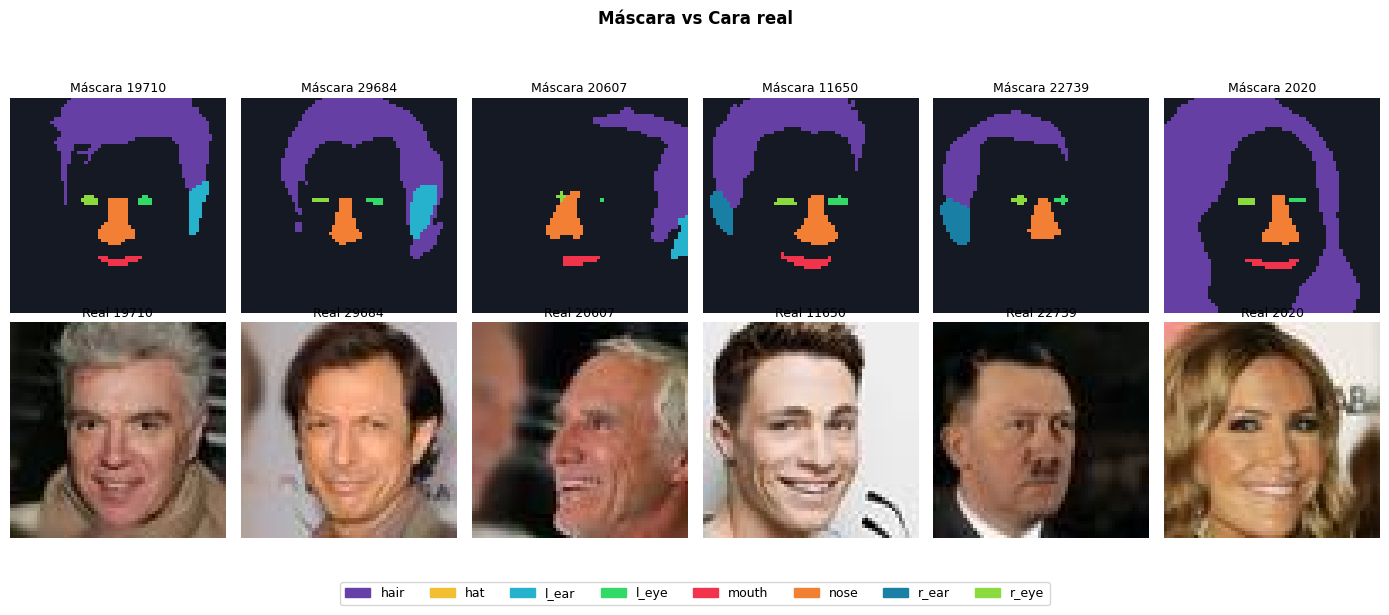

In [100]:
eda_indices = np.random.default_rng(SEED).choice(len(x_val), size=6, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(14, 6.2))
for col_idx, val_idx in enumerate(eda_indices):
    axes[0, col_idx].imshow(colorize_mask(x_val[val_idx]))
    axes[0, col_idx].set_title(f"Máscara {ids_val[val_idx]}", fontsize=9, pad=4)
    axes[0, col_idx].axis("off")

    axes[1, col_idx].imshow(denormalize_image(y_val[val_idx]))
    axes[1, col_idx].set_title(f"Real {ids_val[val_idx]}", fontsize=9, pad=4)
    axes[1, col_idx].axis("off")

legend_handles = [
    mpatches.Patch(color=get_class_color(cls_name, idx), label=cls_name)
    for idx, cls_name in enumerate(MASK_CLASSES)
]
fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=NUM_CLASSES,
    frameon=True,
    fontsize=9,
    bbox_to_anchor=(0.5, 0.01),
)
plt.suptitle("Máscara vs Cara real", fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0.08, 1, 0.94], h_pad=1.8)
plt.show()

In [101]:
# Cálculo del FID y cacheado previo para no entrenar el InceptionV3 en cada evaluación durante el entrenamiento del modelo 
# de difusión. Se extraen las características de las 500 caras reales de validación y se guardan en memoria para compararlas 
# con las caras generadas.

inception_extractor = NoTrainInceptionV3(
    name="inception-v3-compat", features_list=["2048"]
).to(INCEPTION_DEVICE).eval()


def extract_inception_features(images_01: np.ndarray, batch_size: int = FID_BATCH_SIZE) -> torch.Tensor:
    imgs_u8 = np.clip(images_01 * 255.0, 0.0, 255.0).round().astype(np.uint8)
    imgs_nchw = torch.from_numpy(np.ascontiguousarray(np.transpose(imgs_u8, (0, 3, 1, 2))))
    feats = []
    with torch.inference_mode():
        for start in range(0, len(imgs_nchw), batch_size):
            batch = imgs_nchw[start:start + batch_size].to(INCEPTION_DEVICE)
            feats.append(inception_extractor(batch).cpu().double())
    return torch.cat(feats, dim=0)


def compute_fid_from_features(real_feats: torch.Tensor, fake_feats: torch.Tensor) -> float:
    mu_r, mu_f = real_feats.mean(dim=0), fake_feats.mean(dim=0)
    dr, df = real_feats - mu_r, fake_feats - mu_f
    cov_r = (dr.T @ dr) / (len(real_feats) - 1)
    cov_f = (df.T @ df) / (len(fake_feats) - 1)
    return float(_compute_fid(mu_r, cov_r, mu_f, cov_f).item())

y_val_fid_01 = denormalize_image(y_val[:VAL_FID_SAMPLES])
real_val_fid_feats = extract_inception_features(y_val_fid_01)
print(f"Características reales de validación cacheadas: {tuple(real_val_fid_feats.shape)}")

Características reales de validación cacheadas: (500, 2048)


---

## **3. Arquitectura U-Net condicional de difusión y sampler DDIM**

Construimos una U-Net que recibe `[noisy_image (64x64x3), mask (64x64x8), t (entero)]` y predice el ruido ${\epsilon}$ de tamaño `(64x64x3)`:

- **Entrada condicionada:** concatenación `[noisy_image, mask]` de `64x64x11` que pasa por una convolución inicial `3x3` a `64` canales.
- **Paso temporal:** embedding temporal basado en *positional encoding* (similar al de los *Transformers*) seguido de un MLP (`Dense(256) -> SiLU -> Dense(256)`). Dentro de cada bloque residual, el *embedding* temporal aplica una escala y desplazamiento sobre las activaciones normalizadas tras el bloque, permitiendo que la red adapte su comportamiento a todos los niveles de ruido $t \in [0, 999]$.
- **4 escalas (`64 -> 32 -> 16 -> 8`) con filtros `(64, 128, 256, 256)`:** bloques residuales (`GroupNormalization -> SiLU -> Conv2D(3x3) -> GroupNormalization + escala y desplazamiento -> SiLU -> Conv2D(3x3)`), reducción con `Conv2D(3x3, strides=2)` y recuperación con `UpSampling2D("bilinear") + Conv2D(3x3)` más *skip connections* por concatenación.
- ***Self-Attention* espacial (`MultiHeadAttention`, 4 cabezas):** aplicada en `16x16` y en el cuello de botella `8x8` para que cada región espacial atienda a toda la cara, reforzando la simetría.

In [102]:
@keras.saving.register_keras_serializable(package="diffusion_generator")
class SinusoidalTimeEmbedding(layers.Layer):
    """Embedding temporal basado en positional encoding para el paso t."""

    def __init__(self, dim: int = 64, max_period: float = 10000.0, **kwargs):
        super().__init__(**kwargs)
        if dim % 2 != 0:
            raise ValueError("dim debe ser par para el embedding.")
        self.dim = int(dim)
        self.max_period = float(max_period)

    def call(self, timesteps):
        half_dim = self.dim // 2
        t = keras.ops.cast(keras.ops.reshape(timesteps, (-1, 1)), "float32")
        freqs = keras.ops.exp(
            -math.log(self.max_period)
            * keras.ops.arange(half_dim, dtype="float32")
            / max(half_dim - 1, 1)
        )
        args = t * keras.ops.reshape(freqs, (1, half_dim))
        return keras.ops.concatenate([keras.ops.sin(args), keras.ops.cos(args)], axis=-1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], self.dim)

    def get_config(self):
        config = super().get_config()
        config.update({"dim": self.dim, "max_period": self.max_period})
        return config


def residual_block(
    x,
    time_emb,
    out_channels: int,
    dropout: float = 0.0,
    name_prefix: str = "res",
):
    """Bloque residual con GroupNormalization, SiLU, Conv2D(3x3) y modulación temporal."""
    in_channels = x.shape[-1]
    h = layers.GroupNormalization(groups=min(16, in_channels), name=f"{name_prefix}_gn1")(x)
    h = layers.Activation("swish", name=f"{name_prefix}_silu1")(h)
    h = layers.Conv2D(out_channels, kernel_size=3, padding="same", name=f"{name_prefix}_conv1")(h)

    h = layers.GroupNormalization(groups=min(16, out_channels), name=f"{name_prefix}_gn2")(h)
    t_act = layers.Activation("swish", name=f"{name_prefix}_t_silu")(time_emb)
    scale = layers.Dense(
        out_channels,
        kernel_initializer="zeros",
        bias_initializer="ones",
        name=f"{name_prefix}_t_scale",
    )(t_act)
    shift = layers.Dense(
        out_channels,
        kernel_initializer="zeros",
        bias_initializer="zeros",
        name=f"{name_prefix}_t_shift",
    )(t_act)
    scale = layers.Reshape((1, 1, out_channels), name=f"{name_prefix}_t_scale_rs")(scale)
    shift = layers.Reshape((1, 1, out_channels), name=f"{name_prefix}_t_shift_rs")(shift)
    h = layers.Multiply(name=f"{name_prefix}_film_mul")([h, scale])
    h = layers.Add(name=f"{name_prefix}_film_add")([h, shift])

    h = layers.Activation("swish", name=f"{name_prefix}_silu2")(h)
    if dropout > 0.0:
        h = layers.Dropout(dropout, name=f"{name_prefix}_drop")(h)
    h = layers.Conv2D(out_channels, kernel_size=3, padding="same", name=f"{name_prefix}_conv2")(h)

    skip = (
        x
        if in_channels == out_channels
        else layers.Conv2D(out_channels, kernel_size=1, padding="same", name=f"{name_prefix}_skip")(x)
    )
    return layers.Add(name=f"{name_prefix}_out")([skip, h])


def attention_block(x, num_heads: int = 4, name_prefix: str = "attn"):
    """Self-Attention espacial con conexión residual."""
    _, h, w, c = x.shape
    norm = layers.GroupNormalization(groups=min(16, c), name=f"{name_prefix}_gn")(x)
    seq = layers.Reshape((h * w, c), name=f"{name_prefix}_to_seq")(norm)
    attn = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=c // num_heads,
        name=f"{name_prefix}_mha",
    )(seq, seq)
    attn = layers.Reshape((h, w, c), name=f"{name_prefix}_to_grid")(attn)
    return layers.Add(name=f"{name_prefix}_add")([x, attn])


def build_diffusion_unet(
    num_classes: int = NUM_CLASSES,
    filters: tuple[int, ...] = (64, 128, 256, 256),
    time_dim: int = 256,
    name: str = "conditional_diffusion_unet",
) -> keras.Model:
    noisy_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="noisy_image")
    mask_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, num_classes), name="mask_input")
    timestep_input = keras.Input(shape=(), dtype="int32", name="timestep_input")

    # Embedding temporal sinusoidal + MLP
    t_emb = SinusoidalTimeEmbedding(dim=64, name="time_sinusoidal")(timestep_input)
    t_emb = layers.Dense(time_dim, activation="swish", name="time_mlp_1")(t_emb)
    t_emb = layers.Dense(time_dim, name="time_mlp_2")(t_emb)

    # Concatenación [noisy_image, mask] -> (64, 64, 11)
    x = layers.Concatenate(axis=-1, name="cond_concat")([noisy_input, mask_input])
    x = layers.Conv2D(filters[0], kernel_size=3, padding="same", name="stem_conv")(x)

    # Encoder: 64 -> 32 -> 16 -> 8
    skips = []
    for lvl, f in enumerate(filters):
        drop = 0.1 if lvl >= 2 else 0.0
        x = residual_block(x, t_emb, f, dropout=drop, name_prefix=f"enc_l{lvl}_res")
        if lvl == 2:
            x = attention_block(x, num_heads=4, name_prefix="enc_16x16_attn")
        if lvl < len(filters) - 1:
            skips.append(x)
            x = layers.Conv2D(
                f, kernel_size=3, strides=2, padding="same", name=f"enc_l{lvl}_down"
            )(x)

    # Cuello de botella en 8x8
    x = attention_block(x, num_heads=4, name_prefix="mid_8x8_attn")
    x = residual_block(x, t_emb, filters[-1], dropout=0.1, name_prefix="mid_8x8_res")

    # Decoder: 8 -> 16 -> 32 -> 64
    for lvl in reversed(range(len(filters) - 1)):
        f = filters[lvl]
        drop = 0.1 if lvl == 2 else 0.0
        x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear", name=f"dec_l{lvl}_up")(x)
        x = layers.Conv2D(f, kernel_size=3, padding="same", name=f"dec_l{lvl}_up_conv")(x)
        x = layers.Concatenate(axis=-1, name=f"dec_l{lvl}_skip")([x, skips.pop()])
        x = residual_block(x, t_emb, f, dropout=drop, name_prefix=f"dec_l{lvl}_res")
        if lvl == 2:
            x = attention_block(x, num_heads=4, name_prefix="dec_16x16_attn")

    # Cabeza de salida: predicción del ruido (64, 64, 3)
    x = layers.GroupNormalization(groups=min(16, filters[0]), name="out_gn")(x)
    x = layers.Activation("swish", name="out_silu")(x)
    pred_noise = layers.Conv2D(
        CHANNELS,
        kernel_size=3,
        padding="same",
        kernel_initializer="zeros",
        name="pred_noise",
    )(x)

    return keras.Model(
        inputs=[noisy_input, mask_input, timestep_input],
        outputs=pred_noise,
        name=name,
    )


unet = build_diffusion_unet(NUM_CLASSES, name="diffusion_unet")
unet.summary()

Model: "diffusion_unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ noisy_image         │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mask_input          │ (None, 64, 64, 8) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ timestep_input      │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cond_concat         │ (None, 64, 64,    │          0 │ noisy_image[0][0… │
│ (Concatenate)       │ 11)               │            │ mask_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_sinusoidal     │ (None, 64)        │          0 │ timestep_input[0… │
│ (SinusoidalTimeEmb… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 64, 64,    │      6,400 │ cond_concat[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_mlp_1 (Dense)  │ (None, 256)       │     16,640 │ time_sinusoidal[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_l0_res_gn1      │ (None, 64, 64,    │        128 │ stem_conv[0][0]   │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_mlp_2 (Dense)  │ (None, 256)       │     65,792 │ time_mlp_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_l0_res_silu1    │ (None, 64, 64,    │          0 │ enc_l0_res_gn1[0… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_l0_res_t_silu   │ (None, 256)       │          0 │ time_mlp_2[0][0]  │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_l0_res_conv1    │ (None, 64, 64,    │     36,928 │ enc_l0_res_silu1… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_l0_res_t_scale  │ (None, 64)        │     16,448 │ enc_l0_res_t_sil… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_l0_res_gn2      │ (None, 64, 64,    │        128 │ enc_l0_res_conv1… │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_l0_res_t_scale… │ (None, 1, 1, 64)  │          0 │ enc_l0_res_t_sca… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_l0_res_t_shift  │ (None, 64)        │     16,448 │ enc_l0_res_t_sil… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_l0_res_film_mul │ (None, 64, 64,    │          0 │ enc_l0_res_gn2[0… │
│ (Multiply)          │ 64)               │            │ enc_l0_res_t_sca… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 9,423,107 (35.95 MB)

 Trainable params: 9,423,107 (35.95 MB)

 Non-trainable params: 0 (0.00 B)

### **3.1 Esquema de la arquitectura**

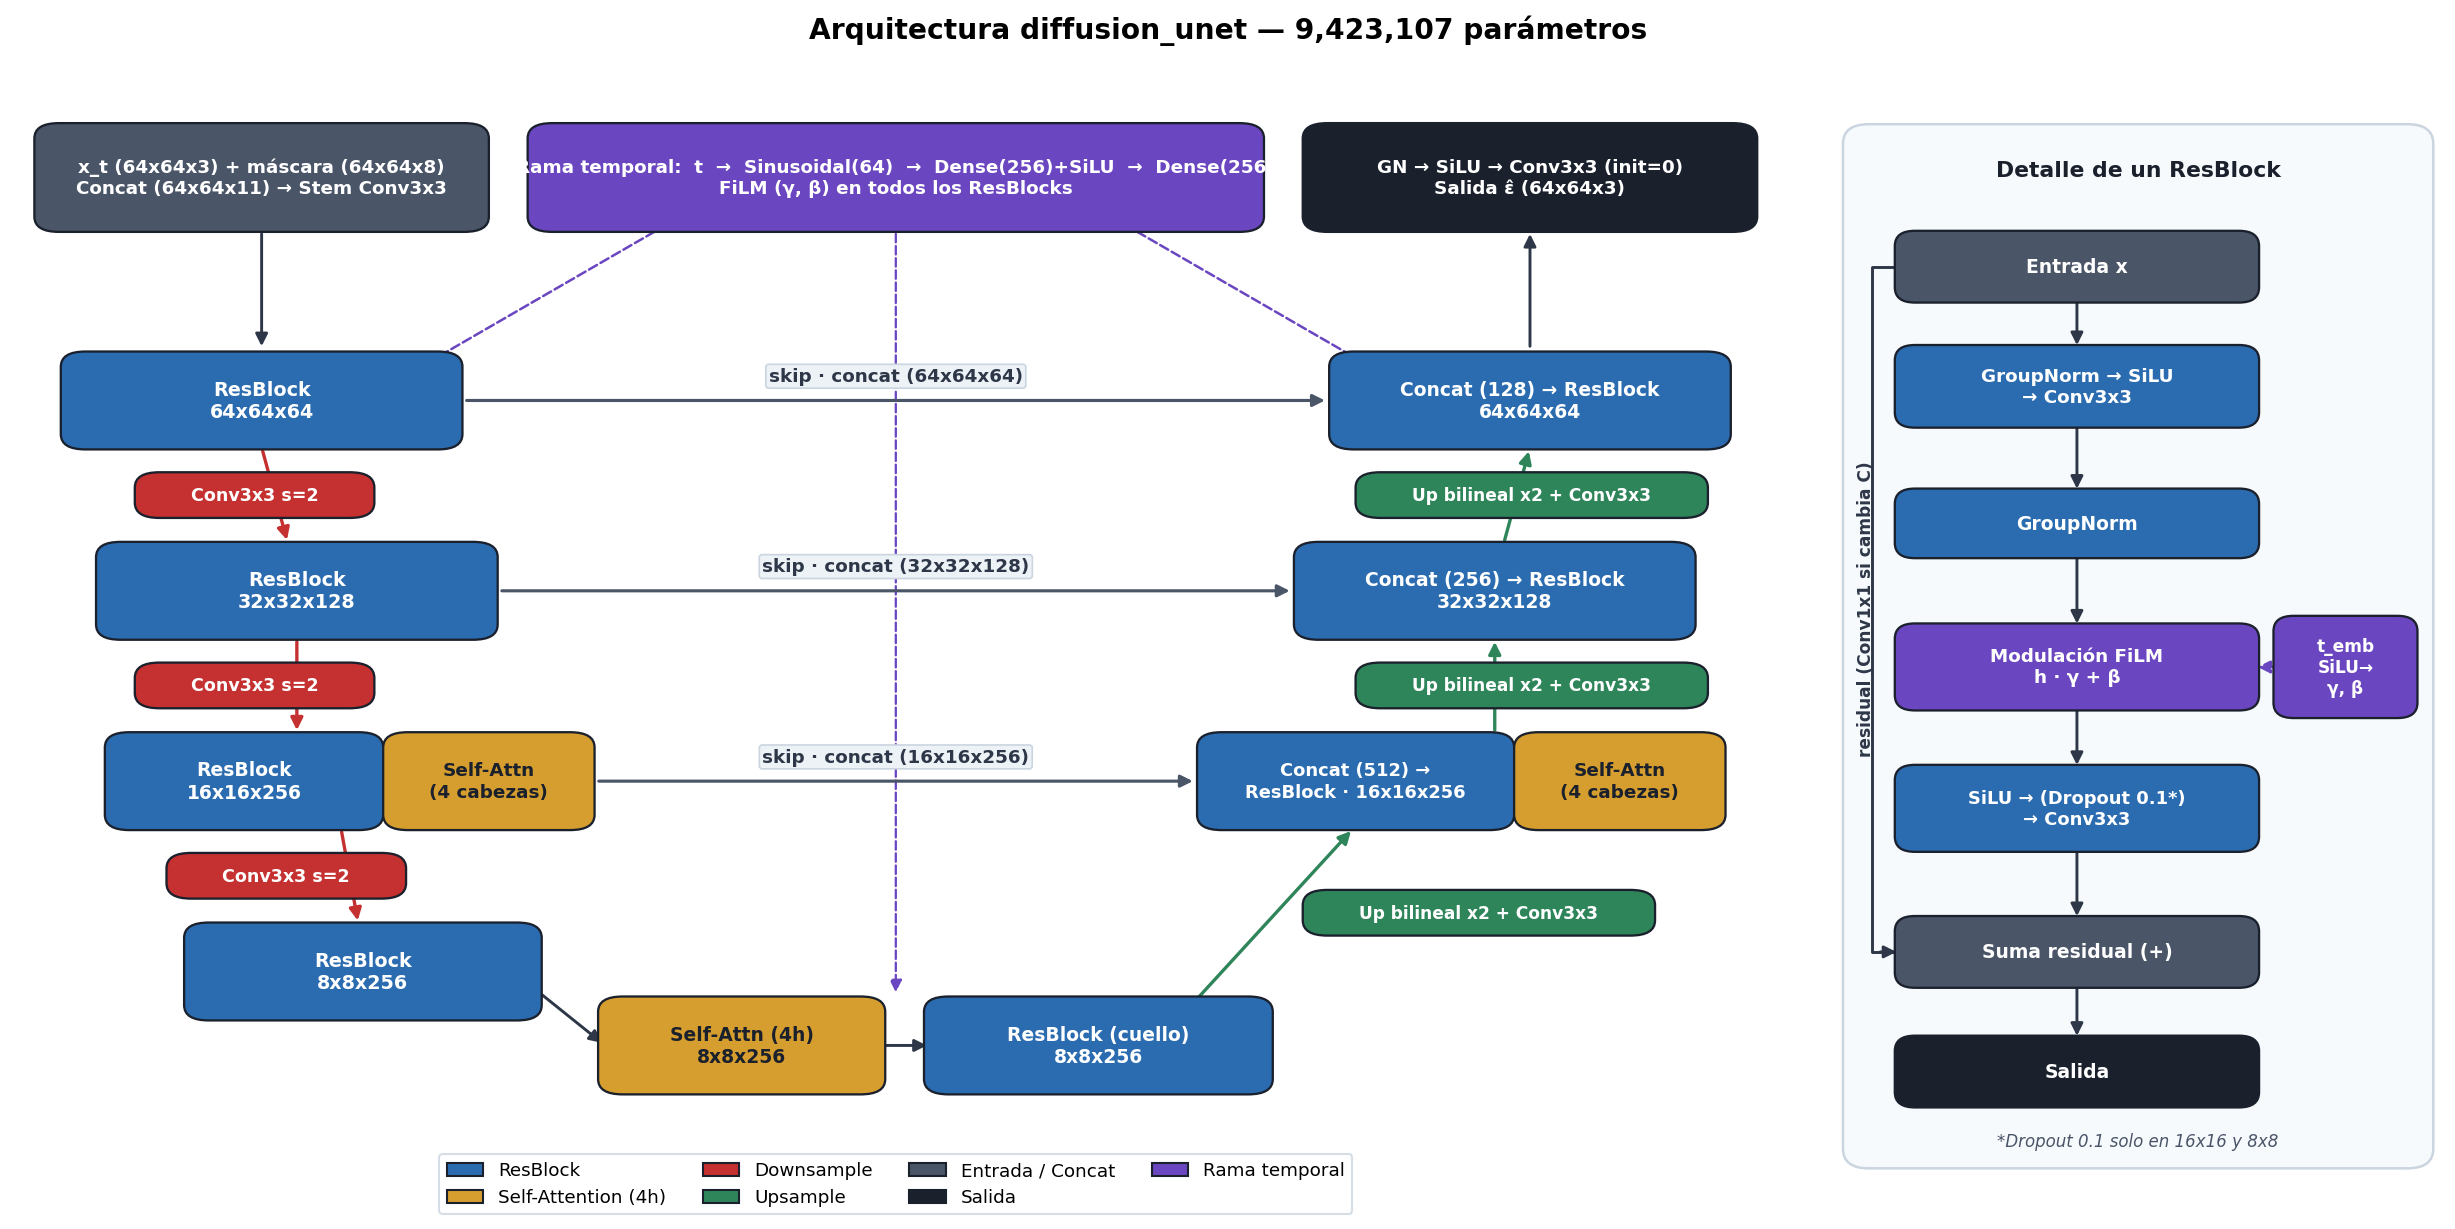

In [ ]:
# Esta función y visualización han sido creadas por Gemini
# La incluimos simplemente a modo informativo para mostrar visualmente la arquitectura

def plot_diffusion_unet_architecture(
    model: keras.Model,
    filters: tuple[int, ...] = (64, 128, 256, 256),
    save_path: Path | None = CHECKPOINT_DIR / "diffusion_unet_architecture.png",
):
    """Dibuja el esquema de la U-Net"""
    
    res = [IMG_SIZE // (2 ** i) for i in range(len(filters))]
    f0, f1, f2, f3 = filters

    # Verificación estricta de las formas reales del modelo
    def _shape(layer_name: str) -> tuple[int, ...]:
        return tuple(int(d) for d in model.get_layer(layer_name).output.shape[1:])

    assert _shape("cond_concat") == (IMG_SIZE, IMG_SIZE, CHANNELS + NUM_CLASSES)
    assert _shape("stem_conv") == (res[0], res[0], f0)
    for i in range(len(filters)):
        assert _shape(f"enc_l{i}_res_out") == (res[i], res[i], filters[i])
    assert _shape("enc_16x16_attn_add") == (res[2], res[2], f2)
    assert _shape("mid_8x8_attn_add") == (res[3], res[3], f3)
    assert _shape("mid_8x8_res_out") == (res[3], res[3], f3)
    for i in (2, 1, 0):
        assert _shape(f"dec_l{i}_res_out") == (res[i], res[i], filters[i])
    assert _shape("dec_16x16_attn_add") == (res[2], res[2], f2)
    assert _shape("pred_noise") == (IMG_SIZE, IMG_SIZE, CHANNELS)

    def _fmt(r: int, c: int) -> str:
        return f"{r}x{r}x{c}"

    C_RES = "#2B6CB0"
    C_ATTN = "#D69E2E"
    C_DOWN = "#C53030"
    C_UP = "#2F855A"
    C_IO = "#4A5568"
    C_OUT = "#1A202C"
    C_TIME = "#6B46C1"

    fig = plt.figure(figsize=(16.5, 8.6), dpi=150)
    gs = fig.add_gridspec(1, 2, width_ratios=[3.35, 1.15], wspace=0.05)
    ax = fig.add_subplot(gs[0, 0])
    ax_r = fig.add_subplot(gs[0, 1])

    ax.set_xlim(0.0, 10.0)
    ax.set_ylim(0.0, 10.2)
    ax.axis("off")

    def draw_box(axis, x, y, w, h, text, facecolor, fontsize=9.0, textcolor="white", edgecolor="#1A202C", lw=1.1, bold=True):
        patch = mpatches.FancyBboxPatch(
            (x, y), w, h,
            boxstyle="round,pad=0.04,rounding_size=0.14",
            facecolor=facecolor, edgecolor=edgecolor, linewidth=lw, zorder=3,
        )
        axis.add_patch(patch)
        axis.text(
            x + w / 2, y + h / 2, text,
            ha="center", va="center", color=textcolor,
            fontsize=fontsize, fontweight="bold" if bold else "normal",
            zorder=4, linespacing=1.22,
        )

    def draw_arrow(axis, p0, p1, color="#2D3748", lw=1.4, style="-|>", ls="-", rad=0.0):
        arr = mpatches.FancyArrowPatch(
            p0, p1,
            arrowstyle=style, mutation_scale=12,
            color=color, linewidth=lw, linestyle=ls,
            connectionstyle=f"arc3,rad={rad}", zorder=2,
        )
        axis.add_patch(arr)

    # Rama temporal
    draw_box(
        ax, 2.95, 8.95, 4.10, 0.92,
        "Rama temporal:  t  →  Sinusoidal(64)  →  Dense(256)+SiLU  →  Dense(256)\n"
        "FiLM (γ, β) en todos los ResBlocks",
        C_TIME, fontsize=8.8,
    )
    # Flechas discontinuas desde la rama temporal hacia encoder, cuello y decoder
    draw_arrow(ax, (3.65, 8.93), (2.25, 7.62), color=C_TIME, lw=1.2, ls="--")
    draw_arrow(ax, (5.00, 8.93), (5.00, 1.88), color=C_TIME, lw=1.1, ls="--")
    draw_arrow(ax, (6.35, 8.93), (7.75, 7.62), color=C_TIME, lw=1.2, ls="--")

    # Entradas y stem (arriba izquierda) 
    draw_box(
        ax, 0.15, 8.95, 2.50, 0.92,
        f"x_t ({_fmt(IMG_SIZE, CHANNELS)}) + máscara ({_fmt(IMG_SIZE, NUM_CLASSES)})\n"
        f"Concat ({_fmt(IMG_SIZE, CHANNELS + NUM_CLASSES)}) → Stem Conv3x3",
        C_IO, fontsize=8.8,
    )
    draw_arrow(ax, (1.40, 8.93), (1.40, 7.82))

    # Salida (arriba derecha)
    draw_box(
        ax, 7.35, 8.95, 2.50, 0.92,
        f"GN → SiLU → Conv3x3 (init=0)\nSalida ε̂ ({_fmt(IMG_SIZE, CHANNELS)})",
        C_OUT, fontsize=8.8,
    )
    draw_arrow(ax, (8.60, 7.82), (8.60, 8.93))

    # Niveles del Encoder (izquierda) y Decoder (derecha)
    y_levels = [6.95, 5.20, 3.45, 1.70]  # niveles 0, 1, 2, 3
    box_h = 0.82

    # Nivel 0 (64x64x64)
    draw_box(ax, 0.30, y_levels[0], 2.20, box_h, f"ResBlock\n{_fmt(res[0], f0)}", C_RES, fontsize=9.2)
    draw_box(ax, 7.50, y_levels[0], 2.20, box_h, f"Concat ({2*f0}) → ResBlock\n{_fmt(res[0], f0)}", C_RES, fontsize=9.0)

    # Nivel 1 (32x32x128)
    draw_box(ax, 0.50, y_levels[1], 2.20, box_h, f"ResBlock\n{_fmt(res[1], f1)}", C_RES, fontsize=9.2)
    draw_box(ax, 7.30, y_levels[1], 2.20, box_h, f"Concat ({2*f1}) → ResBlock\n{_fmt(res[1], f1)}", C_RES, fontsize=9.0)

    # Nivel 2 (16x16x256): ResBlock + Self-Attention (4 cabezas)
    draw_box(ax, 0.55, y_levels[2], 1.50, box_h, f"ResBlock\n{_fmt(res[2], f2)}", C_RES, fontsize=9.0)
    draw_box(ax, 2.13, y_levels[2], 1.12, box_h, "Self-Attn\n(4 cabezas)", C_ATTN, fontsize=8.8, textcolor="#1A202C")
    draw_arrow(ax, (2.05, y_levels[2] + box_h / 2), (2.13, y_levels[2] + box_h / 2), lw=1.2)

    draw_box(ax, 6.75, y_levels[2], 1.72, box_h, f"Concat ({2*f2}) →\nResBlock · {_fmt(res[2], f2)}", C_RES, fontsize=8.6)
    draw_box(ax, 8.55, y_levels[2], 1.12, box_h, "Self-Attn\n(4 cabezas)", C_ATTN, fontsize=8.8, textcolor="#1A202C")
    draw_arrow(ax, (8.47, y_levels[2] + box_h / 2), (8.55, y_levels[2] + box_h / 2), lw=1.2)

    # Nivel 3 (8x8x256): Encoder ResBlock -> Cuello de botella (Self-Attn -> ResBlock)
    draw_box(ax, 1.00, y_levels[3], 1.95, box_h, f"ResBlock\n{_fmt(res[3], f3)}", C_RES, fontsize=9.2)
    draw_box(ax, 3.35, 1.02, 1.55, 0.82, f"Self-Attn (4h)\n{_fmt(res[3], f3)}", C_ATTN, fontsize=9.0, textcolor="#1A202C")
    draw_box(ax, 5.20, 1.02, 1.90, 0.82, f"ResBlock (cuello)\n{_fmt(res[3], f3)}", C_RES, fontsize=9.0)
    draw_arrow(ax, (2.95, y_levels[3] + 0.25), (3.35, 1.43))
    draw_arrow(ax, (4.90, 1.43), (5.20, 1.43))

    # Flechas Downsample (Encoder)
    down_specs = [
        ((1.40, y_levels[0] - 0.02), (1.55, y_levels[1] + box_h + 0.02), 0.72, 6.32),
        ((1.60, y_levels[1] - 0.02), (1.60, y_levels[2] + box_h + 0.02), 0.72, 4.57),
        ((1.85, y_levels[2] - 0.02), (1.95, y_levels[3] + box_h + 0.02), 0.90, 2.82),
    ]
    for p0, p1, bx, by in down_specs:
        draw_arrow(ax, p0, p1, color=C_DOWN, lw=1.6)
        draw_box(ax, bx, by, 1.28, 0.34, "Conv3x3 s=2", C_DOWN, fontsize=8.4)

    # Flechas Upsample (Decoder)
    up_specs = [
        ((6.70, 1.84), (7.60, y_levels[2] - 0.02), 7.35, 2.48),
        ((8.40, y_levels[2] + box_h + 0.02), (8.40, y_levels[1] - 0.02), 7.65, 4.57),
        ((8.45, y_levels[1] + box_h + 0.02), (8.60, y_levels[0] - 0.02), 7.65, 6.32),
    ]
    for p0, p1, bx, by in up_specs:
        draw_arrow(ax, p0, p1, color=C_UP, lw=1.6)
        draw_box(ax, bx, by, 1.92, 0.34, "Up bilineal x2 + Conv3x3", C_UP, fontsize=8.2)

    # Skip connections horizontales (niveles 0, 1 y 2 tras Self-Attn)
    skip_specs = [
        (2.54, 7.46, y_levels[0] + box_h / 2, f"skip · concat ({_fmt(res[0], f0)})"),
        (2.74, 7.26, y_levels[1] + box_h / 2, f"skip · concat ({_fmt(res[1], f1)})"),
        (3.29, 6.71, y_levels[2] + box_h / 2, f"skip · concat ({_fmt(res[2], f2)})"),
    ]
    for x0, x1, ym, lbl in skip_specs:
        draw_arrow(ax, (x0, ym), (x1, ym), color=C_IO, lw=1.5)
        ax.text(
            (x0 + x1) / 2, ym + 0.14, lbl,
            ha="center", va="bottom", fontsize=8.8, fontweight="bold", color="#2D3748",
            bbox=dict(boxstyle="round,pad=0.16", facecolor="#EDF2F7", edgecolor="#CBD5E0", lw=0.8),
            zorder=5,
        )

    # Leyenda inferior 
    legend_items = [
        mpatches.Patch(facecolor=C_RES, edgecolor="#1A202C", label="ResBlock"),
        mpatches.Patch(facecolor=C_ATTN, edgecolor="#1A202C", label="Self-Attention (4h)"),
        mpatches.Patch(facecolor=C_DOWN, edgecolor="#1A202C", label="Downsample"),
        mpatches.Patch(facecolor=C_UP, edgecolor="#1A202C", label="Upsample"),
        mpatches.Patch(facecolor=C_IO, edgecolor="#1A202C", label="Entrada / Concat"),
        mpatches.Patch(facecolor=C_OUT, edgecolor="#1A202C", label="Salida"),
        mpatches.Patch(facecolor=C_TIME, edgecolor="#1A202C", label="Rama temporal"),
    ]
    ax.legend(
        handles=legend_items, loc="lower center", ncol=4, frameon=True,
        fontsize=8.8, bbox_to_anchor=(0.50, -0.02), facecolor="white", edgecolor="#CBD5E0",
    )

    # Panel derecho: Detalle interno de un ResBlock
    ax_r.set_xlim(0.0, 4.2)
    ax_r.set_ylim(0.0, 10.2)
    ax_r.axis("off")

    panel_bg = mpatches.FancyBboxPatch(
        (0.10, 0.35), 4.00, 9.50,
        boxstyle="round,pad=0.05,rounding_size=0.18",
        facecolor="#F7FAFC", edgecolor="#CBD5E0", linewidth=1.2, zorder=1,
    )
    ax_r.add_patch(panel_bg)
    ax_r.text(2.10, 9.48, "Detalle de un ResBlock", ha="center", va="center", fontsize=10.5, fontweight="bold", color="#1A202C")

    rx, rw = 0.45, 2.45
    draw_box(ax_r, rx, 8.30, rw, 0.58, "Entrada x", C_IO, fontsize=9.0)
    draw_box(ax_r, rx, 7.15, rw, 0.68, "GroupNorm → SiLU\n→ Conv3x3", C_RES, fontsize=8.8)
    draw_box(ax_r, rx, 5.95, rw, 0.56, "GroupNorm", C_RES, fontsize=9.0)
    draw_box(ax_r, rx, 4.55, rw, 0.72, "Modulación FiLM\nh · γ + β", C_TIME, fontsize=8.8)
    draw_box(ax_r, rx, 3.25, rw, 0.72, "SiLU → (Dropout 0.1*)\n→ Conv3x3", C_RES, fontsize=8.6)
    draw_box(ax_r, rx, 2.00, rw, 0.58, "Suma residual (+)", C_IO, fontsize=9.0)
    draw_box(ax_r, rx, 0.90, rw, 0.58, "Salida", C_OUT, fontsize=9.0)

    # Entrada de t_emb desde el lateral derecho hacia FiLM
    draw_box(ax_r, 3.08, 4.48, 0.92, 0.86, "t_emb\nSiLU→\nγ, β", C_TIME, fontsize=8.2)
    draw_arrow(ax_r, (3.08, 4.91), (2.90, 4.91), color=C_TIME, lw=1.4, ls="--")

    # Flechas verticales del flujo principal
    for y_top, y_bot in [(8.30, 7.83), (7.15, 6.51), (5.95, 5.27), (4.55, 3.97), (3.25, 2.58), (2.00, 1.48)]:
        draw_arrow(ax_r, (rx + rw / 2, y_top), (rx + rw / 2, y_bot), lw=1.4)

    # Conexión residual (skip) por el borde izquierdo del panel
    ax_r.plot([0.45, 0.25, 0.25, 0.45], [8.59, 8.59, 2.29, 2.29], color="#2D3748", lw=1.4, zorder=2)
    draw_arrow(ax_r, (0.28, 2.29), (0.45, 2.29), color="#2D3748", lw=1.4)
    ax_r.text(
        0.21, 5.45, "residual (Conv1x1 si cambia C)",
        rotation=90, ha="center", va="center", fontsize=8.2, color="#2D3748", fontweight="bold",
    )
    ax_r.text(
        2.10, 0.55, "*Dropout 0.1 solo en 16x16 y 8x8",
        ha="center", va="center", fontsize=8.0, color="#4A5568", style="italic",
    )

    fig.suptitle(
        f"Arquitectura {model.name} — {model.count_params():,} parámetros",
        fontsize=13.5, fontweight="bold", y=0.97,
    )
    fig.subplots_adjust(left=0.01, right=0.99, top=0.91, bottom=0.05)
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_diffusion_unet_architecture(unet)

In [104]:
_DDIM_PREDICT_CACHE = {}

def _get_ddim_predict_fn(model: keras.Model):
    model_id = id(model)
    if model_id not in _DDIM_PREDICT_CACHE:
        @tf.function(
            input_signature=[
                tf.TensorSpec(shape=(None, IMG_SIZE, IMG_SIZE, CHANNELS), dtype=tf.float32),
                tf.TensorSpec(shape=(None, IMG_SIZE, IMG_SIZE, NUM_CLASSES), dtype=tf.float32),
                tf.TensorSpec(shape=(None,), dtype=tf.int32),
            ]
        )
        def _predict_eps(x_in, m_in, t_in):
            return model([x_in, m_in, t_in], training=False)

        _DDIM_PREDICT_CACHE[model_id] = _predict_eps
    return _DDIM_PREDICT_CACHE[model_id]


def ddim_sample(
    model: keras.Model,
    masks: np.ndarray,
    steps: int = EVAL_DDIM_STEPS,
    eta: float = EVAL_DDIM_ETA,
    seed: int | None = None,
    initial_noise: np.ndarray | None = None,
    batch_size: int = BATCH_SIZE,
    schedule=None,
) -> np.ndarray:
    """Genera caras en [-1, 1] desde máscaras mediante muestreo DDIM (determinista si eta=0)."""
    sched = diffusion_schedule if schedule is None else schedule
    single_input = masks.ndim == 3
    masks_4d = masks[None, ...].astype(np.float32) if single_input else masks.astype(np.float32)
    n_samples = len(masks_4d)

    rng = np.random.default_rng(seed)
    if initial_noise is not None:
        noise_all = initial_noise.astype(np.float32)
        if noise_all.ndim == 3:
            noise_all = noise_all[None, ...]
    else:
        noise_all = rng.standard_normal((n_samples, IMG_SIZE, IMG_SIZE, CHANNELS)).astype(np.float32)

    timestep_seq = np.round(np.linspace(sched.timesteps - 1, 0, int(steps))).astype(np.int32)
    alphas_cumprod = sched.alphas_cumprod_np

    _predict_eps = _get_ddim_predict_fn(model)

    outputs = []
    for start in range(0, n_samples, batch_size):
        end = min(start + batch_size, n_samples)
        mask_b = tf.convert_to_tensor(masks_4d[start:end], dtype=tf.float32)
        x_t = tf.convert_to_tensor(noise_all[start:end], dtype=tf.float32)
        cur_bs = end - start

        for i, t_curr in enumerate(timestep_seq):
            t_b = tf.fill((cur_bs,), tf.cast(t_curr, tf.int32))
            eps_pred = _predict_eps(x_t, mask_b, t_b)

            alpha_bar_t = float(alphas_cumprod[int(t_curr)])
            sqrt_alpha_t = math.sqrt(alpha_bar_t)
            sqrt_one_minus_t = math.sqrt(max(0.0, 1.0 - alpha_bar_t))

            pred_x0 = (x_t - sqrt_one_minus_t * eps_pred) / sqrt_alpha_t
            pred_x0 = tf.clip_by_value(pred_x0, -1.0, 1.0)

            if i == len(timestep_seq) - 1:
                x_t = pred_x0
            else:
                alpha_bar_prev = float(alphas_cumprod[int(timestep_seq[i + 1])])
                sigma_t = float(eta) * math.sqrt(
                    max(0.0, (1.0 - alpha_bar_prev) / (1.0 - alpha_bar_t))
                    * max(0.0, 1.0 - (alpha_bar_t / alpha_bar_prev))
                )
                dir_coeff = math.sqrt(max(0.0, 1.0 - alpha_bar_prev - sigma_t ** 2))
                x_t = math.sqrt(alpha_bar_prev) * pred_x0 + dir_coeff * eps_pred
                if sigma_t > 0.0:
                    z = tf.convert_to_tensor(
                        rng.standard_normal((cur_bs, IMG_SIZE, IMG_SIZE, CHANNELS)).astype(np.float32)
                    )
                    x_t = x_t + sigma_t * z

        outputs.append(np.clip(x_t.numpy(), -1.0, 1.0))

    result = np.concatenate(outputs, axis=0)
    return result[0] if single_input else result

---

## **4. *Cosine schedule*, aumentación y clase `ConditionalDDPM`**

- ***Cosine schedule***: gracias a la propiedad reproductiva de las gaussianas, podemos saltar directamente a cualquier paso $t \in \{0, \dots, T-1\}$ en tiempo $\mathcal{O}(1)$ mediante $\bar{\alpha}_t$:
   $$q(x_t \mid x_0) = \mathcal{N}\!\left(x_t;\, \sqrt{\bar{\alpha}_t}\,x_0,\, (1 - \bar{\alpha}_t)\mathbf{I}\right) \quad \Longleftrightarrow \quad x_t = \sqrt{\bar{\alpha}_t}\,x_0 + \sqrt{1 - \bar{\alpha}_t}\,\epsilon, \qquad \epsilon \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$$

Un schedule lineal destruye informacion muy rapido en imágenes pequeñas. Esta curva atenúa la señal de forma suave al inicio y al final, repartiendo la dificultad de reconstrucción de manera mucho más equilibrada. 

   $$\bar{\alpha}_t = \frac{f(t)}{f(0)}, \qquad f(t) = \cos^2\!\left(\frac{t / T + s}{1 + s}\cdot\frac{\pi}{2}\right), \qquad s = 0.008$$

- **Aumentación conjunta máscara + cara (`_prepare_train_sample`):** flip horizontal aleatorio con intercambio de canales simétricos (`l_eye <-> r_eye` y `l_ear <-> r_ear`), seguido con probabilidad `0.35` de una pequeña ampliación (`+2` a `+4` píxeles) y recorte aleatorio a `64x64` (`nearest` para la máscara y `bilinear` para la cara), sin alterar colores.

- **Callback `ValFIDAndTrackerCallback`:** cada `VAL_FID_EVERY = 5` épocas (y en la última), genera las `500` caras de validación con `unet` y **DDIM (`25` pasos, $\eta = 0$)**, registra `logs["val_fid"]`.

Cosine schedule listo (T=1000): alpha_bar[0]=0.99996 | alpha_bar[500]=0.4923 | alpha_bar[999]=2.64e-05


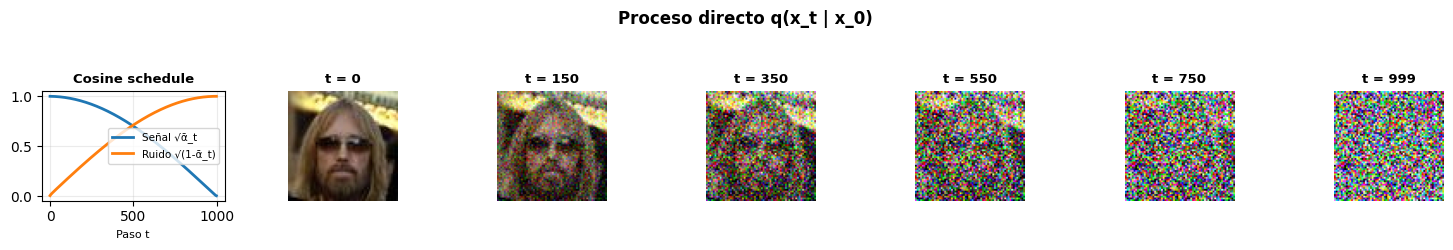

In [105]:
class CosineDiffusionSchedule:
    """Cosine schedule para T pasos."""

    def __init__(self, timesteps: int = TIMESTEPS, s: float = COSINE_S, beta_max: float = 0.2):
        self.timesteps = int(timesteps)
        self.s = float(s)

        steps = np.linspace(0, self.timesteps, self.timesteps + 1, dtype=np.float64)
        f_t = np.cos(((steps / self.timesteps) + self.s) / (1.0 + self.s) * (np.pi / 2.0)) ** 2
        alphas_cumprod_ext = f_t / f_t[0]

        betas = np.clip(1.0 - (alphas_cumprod_ext[1:] / alphas_cumprod_ext[:-1]), 1e-5, beta_max)
        alphas = 1.0 - betas
        alphas_cumprod = np.cumprod(alphas, axis=0)

        self.betas_np = betas.astype(np.float32)
        self.alphas_np = alphas.astype(np.float32)
        self.alphas_cumprod_np = alphas_cumprod.astype(np.float32)
        self.sqrt_alphas_cumprod_np = np.sqrt(alphas_cumprod).astype(np.float32)
        self.sqrt_one_minus_alphas_cumprod_np = np.sqrt(1.0 - alphas_cumprod).astype(np.float32)

        self.sqrt_alphas_cumprod = tf.constant(self.sqrt_alphas_cumprod_np, dtype=tf.float32)
        self.sqrt_one_minus_alphas_cumprod = tf.constant(
            self.sqrt_one_minus_alphas_cumprod_np, dtype=tf.float32
        )

    def q_sample(self, x0: tf.Tensor, t: tf.Tensor, noise: tf.Tensor) -> tf.Tensor:
        """Muestrea q(x_t | x_0) en forma cerrada."""
        a_bar = tf.reshape(tf.gather(self.sqrt_alphas_cumprod, t), (-1, 1, 1, 1))
        one_m_a_bar = tf.reshape(tf.gather(self.sqrt_one_minus_alphas_cumprod, t), (-1, 1, 1, 1))
        return a_bar * x0 + one_m_a_bar * noise


diffusion_schedule = CosineDiffusionSchedule(timesteps=TIMESTEPS, s=COSINE_S)
print(
    f"Cosine schedule listo (T={diffusion_schedule.timesteps}): "
    f"alpha_bar[0]={diffusion_schedule.alphas_cumprod_np[0]:.5f} | "
    f"alpha_bar[500]={diffusion_schedule.alphas_cumprod_np[500]:.4f} | "
    f"alpha_bar[999]={diffusion_schedule.alphas_cumprod_np[-1]:.2e}"
)

# Visualización rápida del proceso directo q(x_t | x_0) sobre una cara de validación
demo_steps = [0, 150, 350, 550, 750, 999]
demo_x0 = tf.convert_to_tensor(y_val[0:1], dtype=tf.float32)
demo_eps = tf.convert_to_tensor(
    np.random.default_rng(SEED).standard_normal(demo_x0.shape).astype(np.float32)
)

fig, axes = plt.subplots(1, len(demo_steps) + 1, figsize=(15, 2.5))
t_axis = np.arange(TIMESTEPS)
axes[0].plot(t_axis, diffusion_schedule.sqrt_alphas_cumprod_np, label="Señal √ᾱ_t", linewidth=2)
axes[0].plot(t_axis, diffusion_schedule.sqrt_one_minus_alphas_cumprod_np, label="Ruido √(1-ᾱ_t)", linewidth=2)
axes[0].set_title("Cosine schedule", fontsize=9.5, fontweight="bold")
axes[0].set_xlabel("Paso t", fontsize=8)
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=7.5, loc="center right")

for idx, t_val in enumerate(demo_steps):
    x_noisy = diffusion_schedule.q_sample(demo_x0, tf.constant([t_val], dtype=tf.int32), demo_eps).numpy()[0]
    axes[idx + 1].imshow(denormalize_image(x_noisy))
    axes[idx + 1].set_title(f"t = {t_val}", fontsize=9.5, fontweight="bold")
    axes[idx + 1].axis("off")

plt.suptitle("Proceso directo q(x_t | x_0)", fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

In [106]:
PROBE_INDICES = np.array([0, 1, 2, 3], dtype=np.int32)
probe_masks = x_val[PROBE_INDICES]
probe_reals = y_val[PROBE_INDICES]
probe_noise = np.random.default_rng(SEED).standard_normal(
    (len(PROBE_INDICES), IMG_SIZE, IMG_SIZE, CHANNELS)
).astype(np.float32)

_FLIP_PERM = list(range(NUM_CLASSES))
for _left_cls, _right_cls in (("l_ear", "r_ear"), ("l_eye", "r_eye")):
    if _left_cls in MASK_CLASSES and _right_cls in MASK_CLASSES:
        _li, _ri = MASK_CLASSES.index(_left_cls), MASK_CLASSES.index(_right_cls)
        _FLIP_PERM[_li], _FLIP_PERM[_ri] = _ri, _li
FLIP_PERM_TENSOR = tf.constant(_FLIP_PERM, dtype=tf.int32)


def _prepare_train_sample(mask_u8, img_u8):
    mask_f = tf.cast(mask_u8, tf.float32)
    img_f = (tf.cast(img_u8, tf.float32) / 127.5) - 1.0

    do_flip = tf.random.uniform(()) > 0.5
    mask_f = tf.cond(
        do_flip,
        lambda: tf.gather(tf.image.flip_left_right(mask_f), FLIP_PERM_TENSOR, axis=-1),
        lambda: mask_f,
    )
    img_f = tf.cond(do_flip, lambda: tf.image.flip_left_right(img_f), lambda: img_f)

    do_affine = tf.random.uniform(()) < 0.35

    def _zoom_and_crop():
        new_sz = tf.random.uniform((), minval=IMG_SIZE + 2, maxval=IMG_SIZE + 5, dtype=tf.int32)
        m_big = tf.image.resize(mask_f, (new_sz, new_sz), method="nearest")
        i_big = tf.image.resize(img_f, (new_sz, new_sz), method="bilinear")
        max_off = new_sz - IMG_SIZE + 1
        oy = tf.random.uniform((), minval=0, maxval=max_off, dtype=tf.int32)
        ox = tf.random.uniform((), minval=0, maxval=max_off, dtype=tf.int32)
        m_crop = tf.image.crop_to_bounding_box(m_big, oy, ox, IMG_SIZE, IMG_SIZE)
        i_crop = tf.image.crop_to_bounding_box(i_big, oy, ox, IMG_SIZE, IMG_SIZE)
        m_crop.set_shape((IMG_SIZE, IMG_SIZE, NUM_CLASSES))
        i_crop.set_shape((IMG_SIZE, IMG_SIZE, CHANNELS))
        return m_crop, i_crop

    return tf.cond(do_affine, _zoom_and_crop, lambda: (mask_f, img_f))


class ConditionalDDPM(keras.Model):
    """Entrenamiento DDPM condicional con predicción de ruido (MSE)."""

    def __init__(
        self,
        unet_model: keras.Model,
        schedule: CosineDiffusionSchedule = diffusion_schedule,
    ):
        super().__init__()
        self.unet = unet_model
        self.schedule = schedule
        self.loss_tracker = keras.metrics.Mean(name="loss")

    @property
    def metrics(self):
        return [self.loss_tracker]

    def call(self, inputs, training: bool = False):
        return self.unet(inputs, training=training)

    def train_step(self, data):
        masks, images = data
        batch_size = tf.shape(images)[0]
        t = tf.random.uniform((batch_size,), minval=0, maxval=self.schedule.timesteps, dtype=tf.int32)
        noise = tf.random.normal(tf.shape(images), dtype=tf.float32)
        noisy_images = self.schedule.q_sample(images, t, noise)

        with tf.GradientTape() as tape:
            pred_noise = self.unet([noisy_images, masks, t], training=True)
            loss = tf.reduce_mean(tf.square(noise - pred_noise))

        grads = tape.gradient(loss, self.unet.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.unet.trainable_variables))

        self.loss_tracker.update_state(loss)
        return {"loss": self.loss_tracker.result()}

    def test_step(self, data):
        masks, images = data
        batch_size = tf.shape(images)[0]
        t = tf.random.uniform((batch_size,), minval=0, maxval=self.schedule.timesteps, dtype=tf.int32)
        noise = tf.random.normal(tf.shape(images), dtype=tf.float32)
        noisy_images = self.schedule.q_sample(images, t, noise)

        pred_noise = self.unet([noisy_images, masks, t], training=False)
        loss = tf.reduce_mean(tf.square(noise - pred_noise))

        self.loss_tracker.update_state(loss)
        return {"loss": self.loss_tracker.result()}


class ValFIDAndTrackerCallback(keras.callbacks.Callback):
    """Evalúa val_fid cada VAL_FID_EVERY épocas con unet y DDIM, y guarda capturas."""

    def __init__(
        self,
        eval_masks: np.ndarray,
        real_feats: torch.Tensor,
        total_epochs: int = EPOCHS,
        every: int = VAL_FID_EVERY,
        ddim_steps: int = VAL_DDIM_STEPS,
        capture_snapshots: bool = True,
    ):
        super().__init__()
        self.eval_masks = eval_masks
        self.real_feats = real_feats
        self.total_epochs = int(total_epochs)
        self.every = int(every)
        self.ddim_steps = int(ddim_steps)
        self.capture_snapshots = bool(capture_snapshots)
        self.epoch_time_s = []
        self.val_fid_epochs = []
        self.val_fid_scores = []
        self.snap_epochs = []
        self.snap_preds = []
        self.best_fid = float("inf")
        self.best_epoch = 0
        self.best_weights = None

    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.time()

    def on_epoch_end(self, epoch, logs=None):
        ep = epoch + 1
        self.epoch_time_s.append(float(time.time() - self.t0))

        if ep % self.every == 0 or ep == self.total_epochs:
            preds = ddim_sample(
                self.model.unet,
                self.eval_masks,
                steps=self.ddim_steps,
                eta=0.0,
                seed=SEED,
                batch_size=BATCH_SIZE,
            )
            fake_feats = extract_inception_features(denormalize_image(preds))
            v_fid = compute_fid_from_features(self.real_feats, fake_feats)
            self.val_fid_epochs.append(ep)
            self.val_fid_scores.append(v_fid)
            if logs is not None:
                logs["val_fid"] = v_fid
            if v_fid < self.best_fid:
                self.best_fid = v_fid
                self.best_epoch = ep
                self.best_weights = self.model.unet.get_weights()

        if self.capture_snapshots and (
            ep == 1 or ep == self.total_epochs or ep % max(1, self.total_epochs // 5) == 0
        ):
            snap = ddim_sample(
                self.model.unet,
                probe_masks,
                steps=self.ddim_steps,
                eta=0.0,
                initial_noise=probe_noise,
                batch_size=len(PROBE_INDICES),
            )
            self.snap_epochs.append(ep)
            self.snap_preds.append(snap)

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.unet.set_weights(self.best_weights)
            print(f"Mejores pesos restaurados de la época {self.best_epoch} (val_fid={self.best_fid:.2f}).")

---

## **5. Entrenamiento y evolución en validación**

In [107]:
steps_per_epoch = int(np.ceil(len(train_records) / BATCH_SIZE))

if TRAIN_MODEL:
    reset_seeds(SEED)
    train_ds = (
        tf.data.Dataset.from_tensor_slices((x_train_u8, y_train_u8))
        .shuffle(buffer_size=len(x_train_u8), seed=SEED, reshuffle_each_iteration=True)
        .map(_prepare_train_sample, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(BATCH_SIZE, drop_remainder=False)
        .prefetch(tf.data.AUTOTUNE)
    )
    val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    unet = build_diffusion_unet(NUM_CLASSES, name="diffusion_unet")

    lr_schedule = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=LR_INIT,
        decay_steps=EPOCHS * steps_per_epoch,
        alpha=COSINE_ALPHA,
    )
    optimizer = keras.optimizers.AdamW(
        learning_rate=lr_schedule,
        weight_decay=WEIGHT_DECAY,
        clipnorm=1.0,
    )

    ddpm = ConditionalDDPM(
        unet_model=unet,
        schedule=diffusion_schedule,
    )
    ddpm.compile(optimizer=optimizer)

    fid_cb = ValFIDAndTrackerCallback(
        x_val[:VAL_FID_SAMPLES],
        real_val_fid_feats,
        total_epochs=EPOCHS,
        every=VAL_FID_EVERY,
        ddim_steps=VAL_DDIM_STEPS,
        capture_snapshots=True,
    )

    print(
        f"Entrenando ConditionalDDPM ({EPOCHS} épocas, {steps_per_epoch} pasos/época, "
        f"AdamW lr={LR_INIT}, wd={WEIGHT_DECAY})...",
        flush=True,
    )
    fit_hist = ddpm.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[fid_cb], verbose=1)

    history = {
        "loss": [float(v) for v in fit_hist.history["loss"]],
        "val_loss": [float(v) for v in fit_hist.history["val_loss"]],
        "epoch_time_s": fid_cb.epoch_time_s,
        "val_fid_epochs": fid_cb.val_fid_epochs,
        "val_fid_scores": [float(v) for v in fid_cb.val_fid_scores],
        "best_val_fid_epoch": int(fid_cb.best_epoch),
        "best_val_fid": float(fid_cb.best_fid),
        "val_ddim_steps": VAL_DDIM_STEPS,
    }

    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    unet.save(UNET_PATH)
    HISTORY_PATH.write_text(json.dumps(history, indent=2))
    np.savez_compressed(
        VAL_EVOLUTION_PATH,
        epochs=np.array(fid_cb.snap_epochs, dtype=np.int32),
        preds=np.array(fid_cb.snap_preds, dtype=np.float32),
        probe_indices=PROBE_INDICES,
    )
    print(f"Checkpoint guardado (U-Net) en {CHECKPOINT_DIR.resolve()}")
else:
    required = [UNET_PATH, HISTORY_PATH, MASK_CLASSES_PATH]
    missing = [str(p) for p in required if not p.exists()]
    if missing:
        raise FileNotFoundError("Faltan checkpoints para TRAIN_MODEL=False: " + ", ".join(missing))
    unet = keras.models.load_model(UNET_PATH, compile=False)
    history = json.loads(HISTORY_PATH.read_text())
    print(
        f"Checkpoint cargado ({len(history['loss'])} épocas, "
        f"mejor val_fid={history.get('best_val_fid', float('nan')):.2f} "
        f"en época {history.get('best_val_fid_epoch', 'N/D')})."
    )

Checkpoint cargado (100 épocas, mejor val_fid=41.52 en época 100).


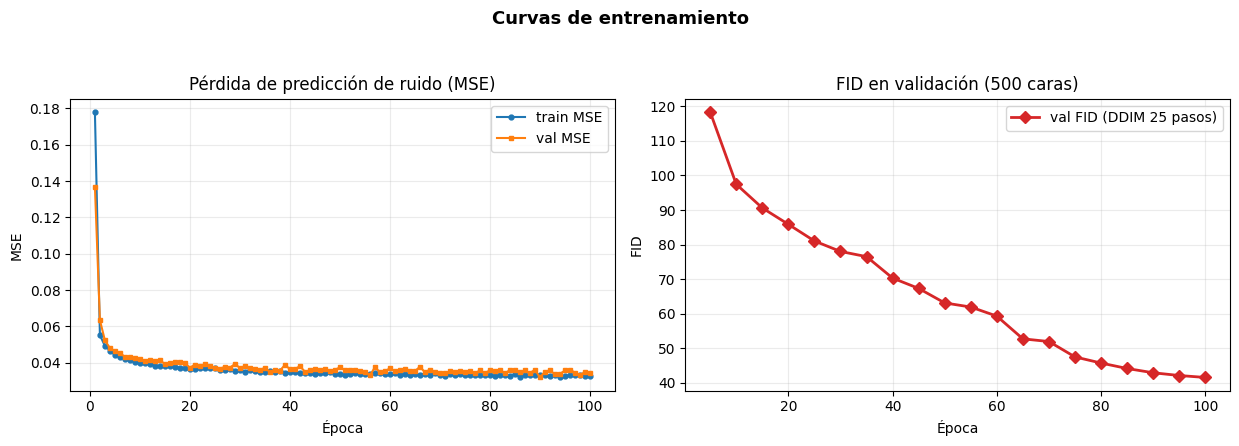

Resumen validación: mejor val_fid en época 100 (41.52) | mejor val_loss en época 90 (0.03192) | tiempo medio/época: 67.6s


In [108]:
epochs_axis = np.arange(1, len(history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

axes[0].plot(epochs_axis, history["loss"], marker="o", markersize=3.5, label="train MSE")
axes[0].plot(epochs_axis, history["val_loss"], marker="s", markersize=3.5, label="val MSE")
axes[0].set_title("Pérdida de predicción de ruido (MSE)")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("MSE")
axes[0].grid(alpha=0.25)
axes[0].legend()

if history.get("val_fid_epochs"):
    axes[1].plot(
        history["val_fid_epochs"],
        history["val_fid_scores"],
        marker="D",
        color="tab:red",
        linewidth=2,
        label=f"val FID (DDIM {history.get('val_ddim_steps', VAL_DDIM_STEPS)} pasos)",
    )
    axes[1].set_title("FID en validación (500 caras)")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("FID")
    axes[1].grid(alpha=0.25)
    axes[1].legend()
else:
    axes[1].axis("off")

plt.suptitle("Curvas de entrenamiento", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

best_mse_ep = int(np.argmin(history["val_loss"])) + 1
print(
    f"Resumen validación: mejor val_fid en época {history.get('best_val_fid_epoch', 'N/D')} "
    f"({history.get('best_val_fid', float('nan')):.2f}) | "
    f"mejor val_loss en época {best_mse_ep} ({min(history['val_loss']):.5f}) | "
    f"tiempo medio/época: {np.mean(history['epoch_time_s']):.1f}s"
)

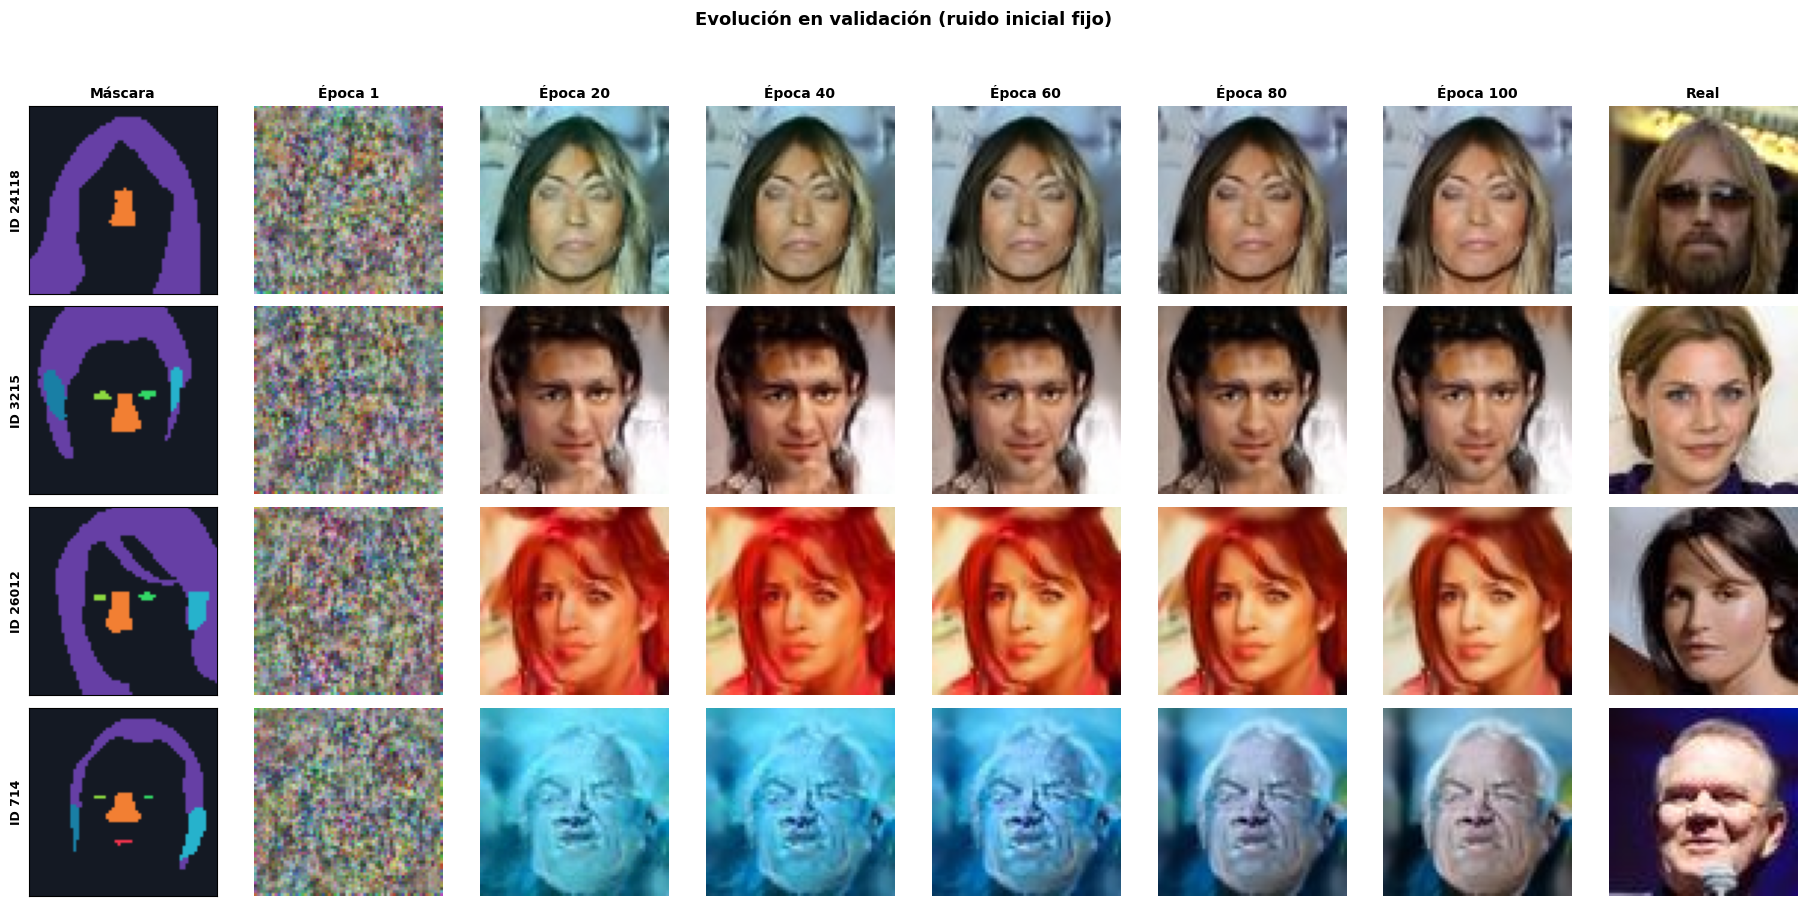

In [109]:
if VAL_EVOLUTION_PATH.exists():
    evo_data = np.load(VAL_EVOLUTION_PATH)
    snap_epochs = evo_data["epochs"]
    snap_preds = evo_data["preds"]
else:
    snap_epochs = np.array([len(history["loss"])])
    snap_preds = ddim_sample(unet, probe_masks, steps=VAL_DDIM_STEPS, eta=0.0, initial_noise=probe_noise)[None, ...]

n_rows = len(PROBE_INDICES)
n_cols = len(snap_epochs) + 2
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.3 * n_cols, 2.3 * n_rows))

for r_idx in range(n_rows):
    axes[r_idx, 0].imshow(colorize_mask(probe_masks[r_idx]))
    axes[r_idx, 0].set_title("Máscara" if r_idx == 0 else "", fontsize=10, fontweight="bold")
    axes[r_idx, 0].set_ylabel(f"ID {ids_val[PROBE_INDICES[r_idx]]}", fontsize=9, fontweight="bold")
    axes[r_idx, 0].set_xticks([])
    axes[r_idx, 0].set_yticks([])

    for c_idx, ep_num in enumerate(snap_epochs):
        axes[r_idx, c_idx + 1].imshow(denormalize_image(snap_preds[c_idx, r_idx]))
        axes[r_idx, c_idx + 1].set_title(f"Época {ep_num}" if r_idx == 0 else "", fontsize=10, fontweight="bold")
        axes[r_idx, c_idx + 1].axis("off")

    axes[r_idx, -1].imshow(denormalize_image(probe_reals[r_idx]))
    axes[r_idx, -1].set_title("Real" if r_idx == 0 else "", fontsize=10, fontweight="bold")
    axes[r_idx, -1].axis("off")

plt.suptitle("Evolución en validación (ruido inicial fijo)", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

---

## **6. Estudio de muestreo DDIM y selección del mejor método (sin reentrenar)**

En un modelo de difusión, la calidad final de las caras depende tanto de los pesos aprendidos por `unet` como de los **parámetros del muestreador DDIM** empleados en inferencia. Con los mismos pesos ya entrenados durante `100` epochs con el objetivo estándar de DDPM ($T = 1000$), podemos generar caras con DDIM y ajustar tanto el número de pasos (`steps`) como la estocasticidad (`eta`) sin reentrenar nada.

### **6.1 Por qué entrenar con DDPM permite muestrear con DDIM**

- **DDPM** asume un proceso directo **markoviano** en el que cada transición $q(x_t \mid x_{t-1})$ añade un incremento muy pequeño de ruido. Por ello, su proceso inverso también es markoviano y estocástico, y requiere recorrer muchos pasos pequeños.
- **DDIM** es un proceso directo **no markoviano** $q_\sigma(x_{t-1} \mid x_t, x_0)$ que conserva **las mismas distribuciones marginales** $q(x_t \mid x_0)$ para todo $t$. Al compartir las mismas marginales, el objetivo que optimiza el predictor de ruido $\epsilon_\theta(x_t, x_{\text{mask}}, t)$ es **igual** al de DDPM.

### **6.2 Saltos DDIM, $\eta \in [0, 1]$ y los pasos (`steps`)**

Matemáticamente, una vez entrenado $\epsilon_\theta$, podemos elegir una secuencia de pasos. En cada salto $t \to t_{\text{prev}}$, estimamos primero la cara limpia $\hat{x}_0$ a partir del ruido predicho $\hat{\epsilon} = \epsilon_\theta(x_t, x_{\text{mask}}, t)$:

$$\hat{x}_0 = \frac{x_t - \sqrt{1 - \bar{\alpha}_t}\,\hat{\epsilon}}{\sqrt{\bar{\alpha}_t}}$$

y calculamos el siguiente estado $x_{t_{\text{prev}}}$:

$$x_{t_{\text{prev}}} = \underbrace{\sqrt{\bar{\alpha}_{t_{\text{prev}}}}\,\hat{x}_0}_{\text{1. Cara limpia estimada}} \;+\; \underbrace{\sqrt{1 - \bar{\alpha}_{t_{\text{prev}}} - \sigma_t^2}\,\hat{\epsilon}}_{\text{2. Dirección del ruido predicho}} \;+\; \underbrace{\sigma_t\,z}_{\text{3. Ruido gaussiano}}, \qquad \sigma_t = \eta\,\sqrt{\frac{1 - \bar{\alpha}_{t_{\text{prev}}}}{1 - \bar{\alpha}_t}}\sqrt{1 - \frac{\bar{\alpha}_t}{\bar{\alpha}_{t_{\text{prev}}}}}$$

- **Con $\eta = 0$ ($\sigma_t = 0$, determinista):** la trayectoria está fijada por el ruido inicial $x_{999}$. Sin embargo, al avanzar de forma rígida, si en los primeros pasos la red introduce un tinte de color o un contraste extraño, ese desvío no puede salvarse y se arrastra hasta $t = 0$.
- **Con $\eta > 0$ (hasta $\eta = 1$, estocástico):** se reintroduce ruido gaussiano $\sigma_t z$ en cada salto (reduciendo proporcionalmente el peso de $\hat{\epsilon}$), recuperando la idea de DDPM de añadir algo de ruido durante la generación. Ese ruido ayuda a borrar parcialmente pequeños errores acumulados en pasos previos.
- **Número de pasos (`steps`):** a más pasos, mayor precisión en la trayectoria inversa, pero también mayor coste computacional.

En los dos experimentos siguientes evaluamos estas configuraciones sobre las `500` caras cacheadas de validación usando `unet` y `ddim_sample`:
1. **Pruebas con $\eta$:** evaluamos **$\eta \in \{0.0, 0.5, 1.0\}$** con `DDIM 50` para medir cómo afecta la estocasticidad a la calidad y naturalidad de las caras.
2. **Pruebas de pasos:** fijando el mejor $\eta$, evaluamos **DDIM con `10`, `25`, `50` y `100` pasos**.

In [110]:
# Garantizamos que unet esté disponible en memoria (p. ej. tras reiniciar el kernel)
if "unet" not in globals() or unet is None:
    if not UNET_PATH.exists():
        raise FileNotFoundError(f"No se encontró el checkpoint {UNET_PATH}.")
    unet = keras.models.load_model(UNET_PATH, compile=False)
    print(f"Cargado unet desde {UNET_PATH.name}")
else:
    print(f"Modelo unet listo en memoria ({unet.count_params():,} parámetros).")

Modelo unet listo en memoria (9,423,107 parámetros).


Resultados cargados de diffusion_generator_sampling_study_unet.json


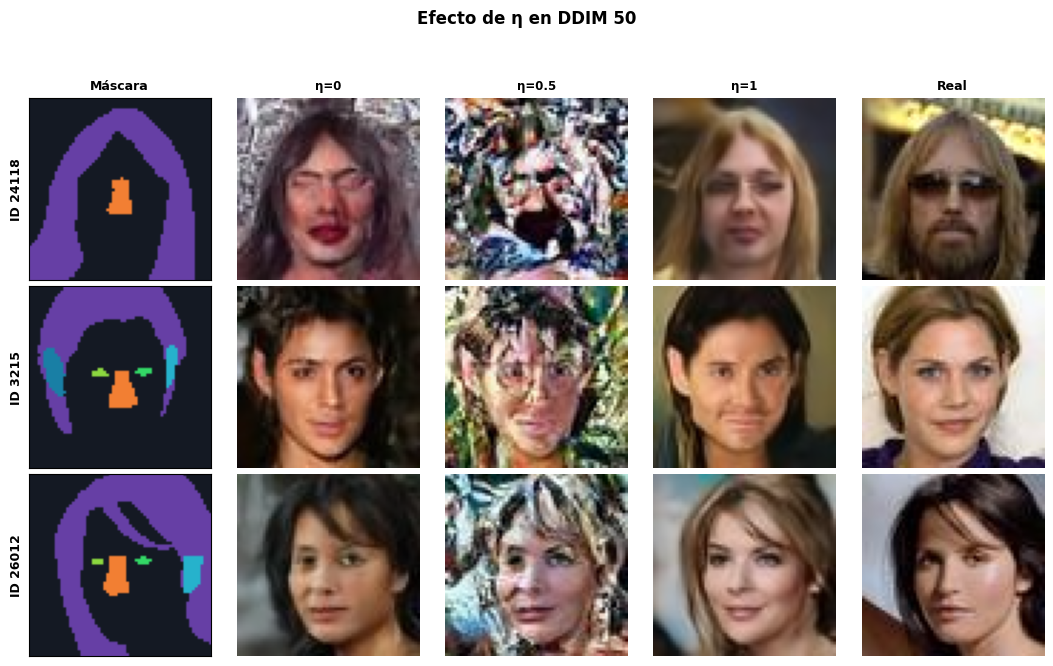

,Configuración,Pasos,eta,val_FID (500),Tiempo / lote (s),Tiempo 500 (s)
0,DDIM 10 (η=1),10,1.0,50.49,0.958,7.66
1,DDIM 25 (η=1),25,1.0,40.35,2.364,18.91
2,DDIM 50 (η=1),50,1.0,37.47,4.705,37.64
3,DDIM 100 (η=1),100,1.0,37.40,9.398,75.18


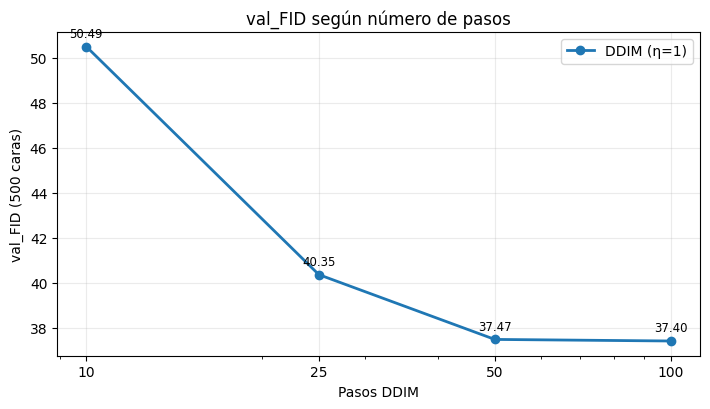

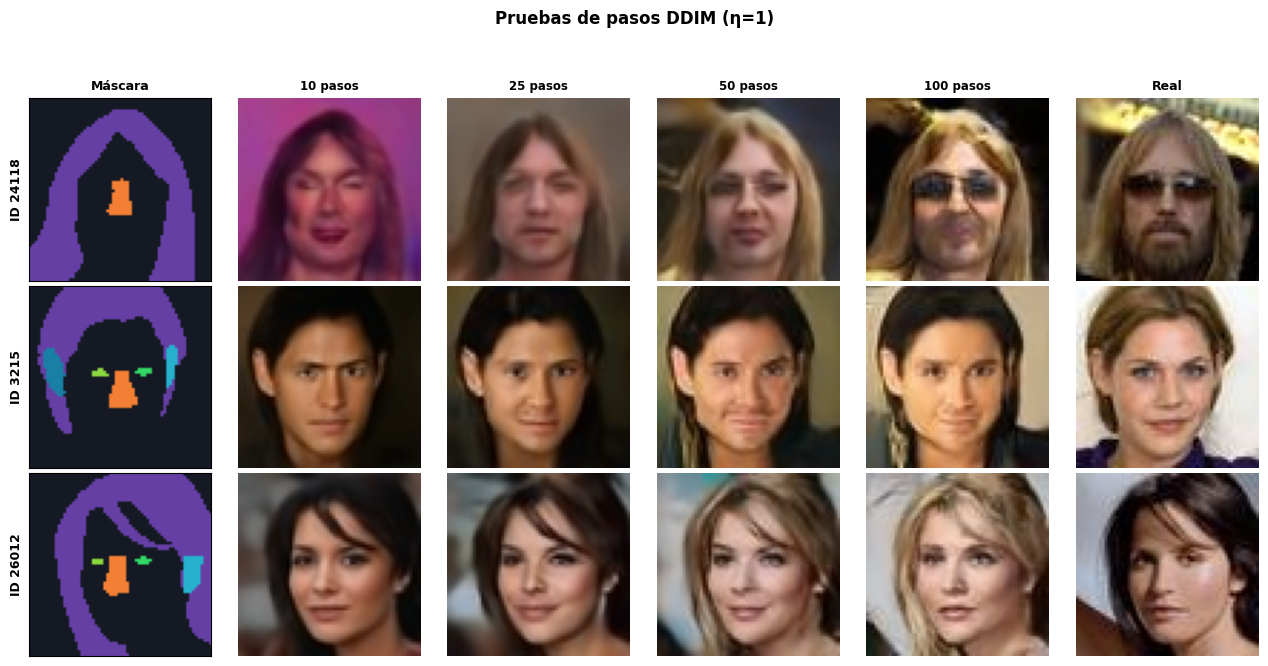

In [ ]:
# Pruebas de muestreo DDIM sobre las 500 caras de validación usando unet
SAMPLING_STUDY_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_sampling_study_unet.json"

ETA_GRID = (0.0, 0.5, 1.0)
STEPS_GRID = (10, 25, 50, 100)

val_masks_study = x_val[:VAL_FID_SAMPLES]
n_batches_val = int(np.ceil(VAL_FID_SAMPLES / BATCH_SIZE))


def _canonical_label(steps: int, eta: float) -> str:
    return f"DDIM {steps} (η={eta:g})"


if SAMPLING_STUDY_PATH.exists():
    sampling_study = json.loads(SAMPLING_STUDY_PATH.read_text())
    print(f"Resultados cargados de {SAMPLING_STUDY_PATH.name}")
else:
    _eval_cache = {}

    def _run_or_cached(steps: int, eta: float) -> dict:
        key = (int(steps), round(float(eta), 4))
        label = _canonical_label(*key)
        if key in _eval_cache:
            return dict(_eval_cache[key])

        print(f"Probando {label}...", end=" ", flush=True)
        t0 = time.time()
        preds_cfg = ddim_sample(
            unet,
            val_masks_study,
            steps=steps,
            eta=eta,
            seed=SEED,
            batch_size=BATCH_SIZE,
        )
        elapsed_s = float(time.time() - t0)
        fake_feats_cfg = extract_inception_features(denormalize_image(preds_cfg))
        v_fid = compute_fid_from_features(real_val_fid_feats, fake_feats_cfg)
        rec = {
            "label": label,
            "steps": int(steps),
            "eta": float(eta),
            "val_fid": round(v_fid, 2),
            "time_per_batch_s": round(elapsed_s / n_batches_val, 3),
            "total_time_s": round(elapsed_s, 2),
        }
        _eval_cache[key] = rec
        print(f"FID={rec['val_fid']:.2f} ({rec['total_time_s']:.1f}s)", flush=True)
        return dict(rec)

    exp_a = [_run_or_cached(50, eta_val) for eta_val in ETA_GRID]
    best_a = min(exp_a, key=lambda r: r["val_fid"])
    best_eta = float(best_a["eta"])
    print(f"Mejor η: {best_eta:g} (FID={best_a['val_fid']:.2f})", flush=True)

    exp_b = [_run_or_cached(st, best_eta) for st in STEPS_GRID]

    sampling_study = {
        "eta_grid": list(ETA_GRID),
        "steps_grid": list(STEPS_GRID),
        "exp_a": exp_a,
        "best_eta": best_eta,
        "exp_b": exp_b,
        "all_results": list(_eval_cache.values()),
    }
    SAMPLING_STUDY_PATH.write_text(json.dumps(sampling_study, indent=2, ensure_ascii=False))
    print(f"Resultados guardados en {SAMPLING_STUDY_PATH.name}", flush=True)

exp_a_results = sampling_study["exp_a"]
best_eta = float(sampling_study["best_eta"])
exp_b_results = sampling_study["exp_b"]

# Caras fijas de validación y ruido inicial compartido para las comparativas visuales
val_vis_indices = np.array([0, 1, 2], dtype=np.int32)
val_vis_masks = x_val[val_vis_indices]
val_vis_noise = np.random.default_rng(SEED + 7).standard_normal(
    (len(val_vis_indices), IMG_SIZE, IMG_SIZE, CHANNELS)
).astype(np.float32)
_vis_cache = {}


def _get_vis_preds(steps: int, eta: float) -> np.ndarray:
    key = (int(steps), round(float(eta), 4))
    if key not in _vis_cache:
        _vis_cache[key] = ddim_sample(
            unet,
            val_vis_masks,
            steps=steps,
            eta=eta,
            seed=SEED + 7,
            initial_noise=val_vis_noise,
            batch_size=len(val_vis_indices),
        )
    return _vis_cache[key]


def _plot_vis_comparison(col_specs: list[tuple[str, np.ndarray]], title: str):
    n_rows_v = len(val_vis_indices)
    n_cols_v = len(col_specs) + 2
    fig, axes = plt.subplots(n_rows_v, n_cols_v, figsize=(2.15 * n_cols_v, 2.25 * n_rows_v))
    for r_idx, v_idx in enumerate(val_vis_indices):
        axes[r_idx, 0].imshow(colorize_mask(x_val[v_idx]))
        axes[r_idx, 0].set_ylabel(f"ID {ids_val[v_idx]}", fontsize=9, fontweight="bold")
        axes[r_idx, 0].set_xticks([])
        axes[r_idx, 0].set_yticks([])
        if r_idx == 0:
            axes[r_idx, 0].set_title("Máscara", fontsize=9, fontweight="bold")

        for c_idx, (col_label, preds_arr) in enumerate(col_specs):
            axes[r_idx, c_idx + 1].imshow(denormalize_image(preds_arr[r_idx]))
            axes[r_idx, c_idx + 1].axis("off")
            if r_idx == 0:
                axes[r_idx, c_idx + 1].set_title(col_label, fontsize=8.5, fontweight="bold")

        axes[r_idx, -1].imshow(denormalize_image(y_val[v_idx]))
        axes[r_idx, -1].axis("off")
        if r_idx == 0:
            axes[r_idx, -1].set_title("Real", fontsize=9, fontweight="bold")

    plt.suptitle(title, fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()


# Comparativa visual de η (mismo ruido inicial)
_plot_vis_comparison(
    [(f"η={r['eta']:g}", _get_vis_preds(r["steps"], r["eta"])) for r in exp_a_results],
    "Efecto de η en DDIM 50",
)

# Pruebas de pasos DDIM con el mejor eta
exp_b_df = pd.DataFrame([
    {
        "Configuración": r["label"],
        "Pasos": r["steps"],
        "eta": r["eta"],
        "val_FID (500)": f"{r['val_fid']:.2f}",
        "Tiempo / lote (s)": f"{r['time_per_batch_s']:.3f}",
        "Tiempo 500 (s)": f"{r['total_time_s']:.2f}",
    }
    for r in exp_b_results
])
display(exp_b_df)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(
    [r["steps"] for r in exp_b_results],
    [r["val_fid"] for r in exp_b_results],
    marker="o",
    linewidth=2,
    label=f"DDIM (η={best_eta:g})",
)
for r in exp_b_results:
    ax.annotate(f"{r['val_fid']:.2f}", (r["steps"], r["val_fid"]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8.5)
ax.set_xscale("log")
ax.set_xticks(list(STEPS_GRID))
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_title("val_FID según número de pasos")
ax.set_xlabel("Pasos DDIM")
ax.set_ylabel("val_FID (500 caras)")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

_plot_vis_comparison(
    [(f"{r['steps']} pasos", _get_vis_preds(r["steps"], r["eta"])) for r in exp_b_results],
    f"Pruebas de pasos DDIM (η={best_eta:g})",
)

In [112]:
# Tabla resumen global y selección automática de los mejores parámetros DDIM
all_sorted = sorted(sampling_study["all_results"], key=lambda r: r["val_fid"])
summary_df = pd.DataFrame([
    {
        "Configuración": r["label"],
        "Pasos": r["steps"],
        "eta": r["eta"],
        "val_FID (500)": f"{r['val_fid']:.2f}",
        "Tiempo / lote (s)": f"{r['time_per_batch_s']:.3f}",
        "Tiempo 500 (s)": f"{r['total_time_s']:.2f}",
    }
    for r in all_sorted
])
print("Resumen de pruebas (ordenado por val_FID):")
display(summary_df)

BEST_EVAL_CFG = all_sorted[0]
BEST_STEPS = int(BEST_EVAL_CFG["steps"])
BEST_ETA = float(BEST_EVAL_CFG["eta"])
BEST_SAMPLER_LABEL = f"DDIM {BEST_STEPS} pasos, η={BEST_ETA:g}"


def generate(
    masks: np.ndarray,
    steps: int | None = None,
    eta: float | None = None,
    seed: int | None = None,
    initial_noise: np.ndarray | None = None,
    batch_size: int = BATCH_SIZE,
) -> np.ndarray:
    """Genera caras usando unet y DDIM con los parámetros ganadores (BEST_STEPS, BEST_ETA)."""
    return ddim_sample(
        unet,
        masks,
        steps=BEST_STEPS if steps is None else steps,
        eta=BEST_ETA if eta is None else eta,
        seed=seed,
        initial_noise=initial_noise,
        batch_size=batch_size,
    )


print(f"Mejor configuración: {BEST_SAMPLER_LABEL} (val_FID={BEST_EVAL_CFG['val_fid']:.2f})")

Resumen de pruebas (ordenado por val_FID):


,Configuración,Pasos,eta,val_FID (500),Tiempo / lote (s),Tiempo 500 (s)
0,DDIM 100 (η=1),100,1.0,37.40,9.398,75.18
1,DDIM 50 (η=1),50,1.0,37.47,4.705,37.64
2,DDIM 50 (η=0.5),50,0.5,39.45,4.720,37.76
3,DDIM 25 (η=1),25,1.0,40.35,2.364,18.91
4,DDIM 50 (η=0),50,0.0,42.83,4.742,37.94
5,DDIM 10 (η=1),10,1.0,50.49,0.958,7.66


Mejor configuración: DDIM 100 pasos, η=1 (val_FID=37.40)


---

## **7. Evaluación en `test`, diversidad y mezcla de caras**

1. **Visualización en `test`:** comparamos `Máscara`, `Generada`, `Real` y `Error |y - ŷ|` sobre ejemplos de test.
2. **Visualización de diversidad (`4` máscaras $\times$ `5` muestras):** generamos 5 caras distintas para cada máscara cambiando solo la semilla del ruido inicial $x_T$.
3. **Mezcla de caras (`mix_faces`):** combinamos atributos de `2` o `3` personas de `test`.

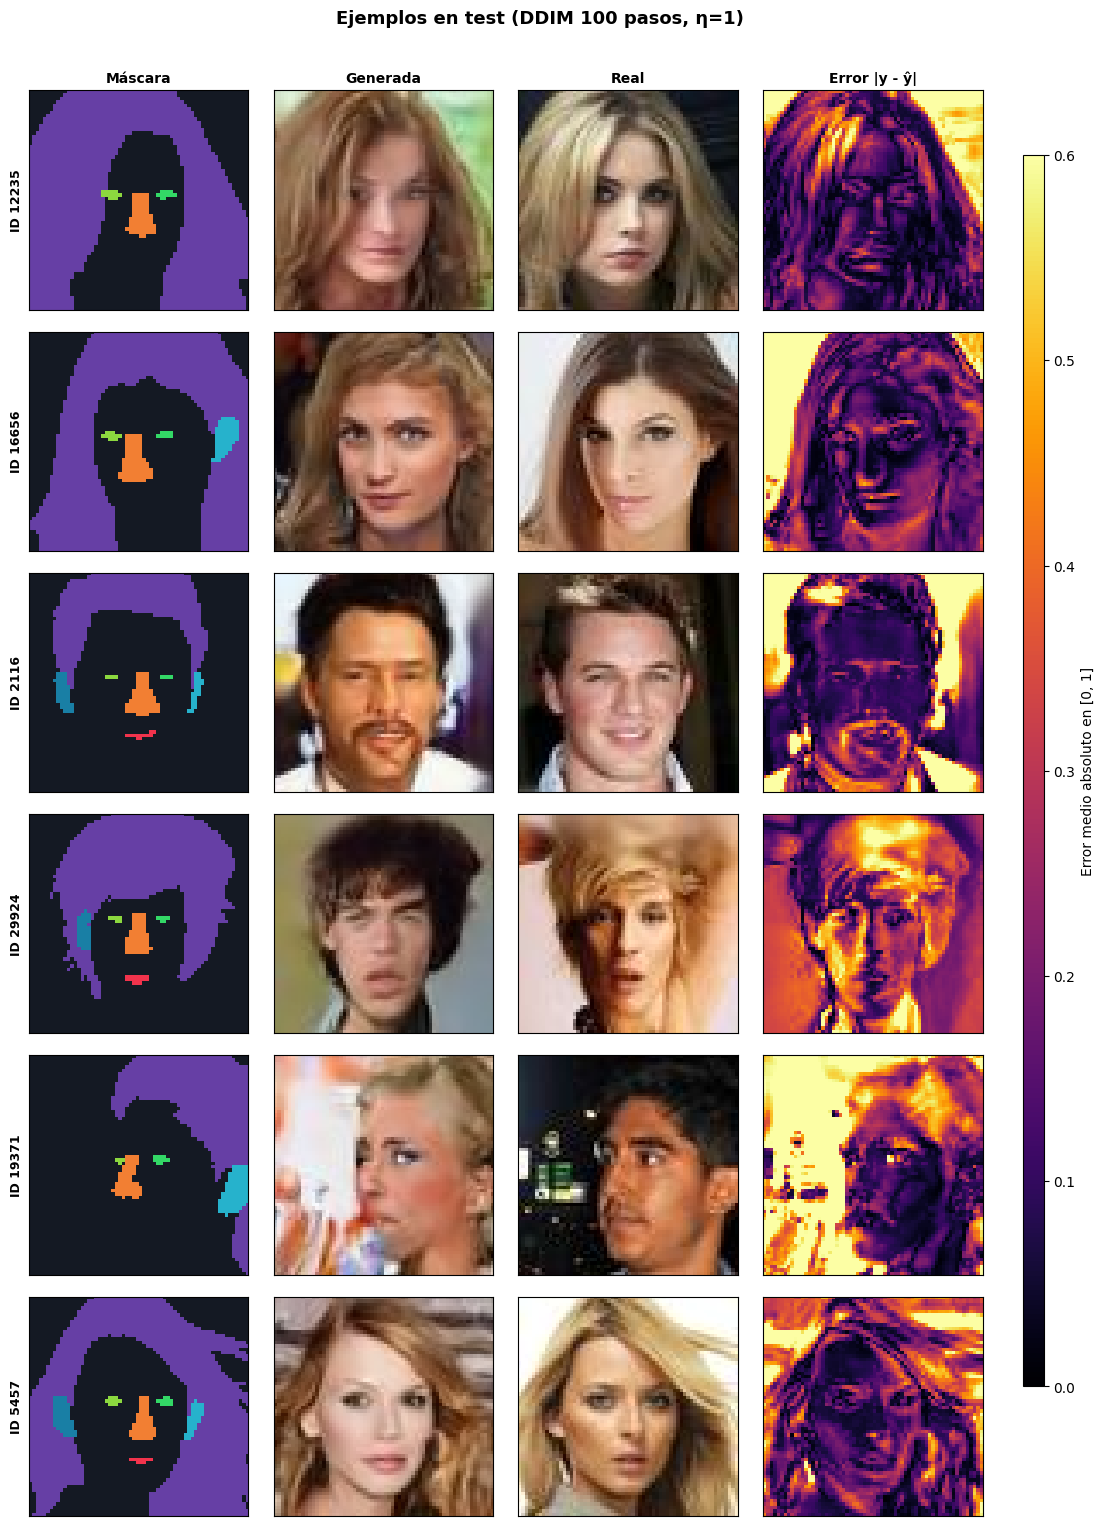

In [113]:
qual_indices = np.random.default_rng(SEED).choice(len(x_test), size=6, replace=False)
qual_preds = generate(x_test[qual_indices], seed=SEED, batch_size=len(qual_indices))

fig, axes = plt.subplots(len(qual_indices), 4, figsize=(11.5, 2.7 * len(qual_indices)))
col_titles = ["Máscara", "Generada", "Real", "Error |y - ŷ|"]
last_im = None

for row_idx, t_idx in enumerate(qual_indices):
    gen_rgb = denormalize_image(qual_preds[row_idx])
    real_rgb = denormalize_image(y_test[t_idx])
    abs_err = np.mean(np.abs(real_rgb - gen_rgb), axis=-1)

    axes[row_idx, 0].imshow(colorize_mask(x_test[t_idx]))
    axes[row_idx, 1].imshow(gen_rgb)
    axes[row_idx, 2].imshow(real_rgb)
    last_im = axes[row_idx, 3].imshow(abs_err, cmap="inferno", vmin=0.0, vmax=0.6)
    axes[row_idx, 0].set_ylabel(f"ID {ids_test[t_idx]}", fontsize=9, fontweight="bold")
    for c_idx in range(4):
        if row_idx == 0:
            axes[row_idx, c_idx].set_title(col_titles[c_idx], fontsize=10, fontweight="bold")
        axes[row_idx, c_idx].set_xticks([])
        axes[row_idx, c_idx].set_yticks([])

cbar_ax = fig.add_axes([0.92, 0.12, 0.018, 0.76])
fig.colorbar(last_im, cax=cbar_ax, label="Error medio absoluto en [0, 1]")
fig.suptitle(f"Ejemplos en test ({BEST_SAMPLER_LABEL})", fontsize=13, fontweight="bold", y=0.97)
fig.subplots_adjust(left=0.05, right=0.89, top=0.92, bottom=0.04, hspace=0.10, wspace=0.06)
fig.savefig(CHECKPOINT_DIR / "diffusion_test_grid.png", dpi=140, bbox_inches="tight")
plt.show()

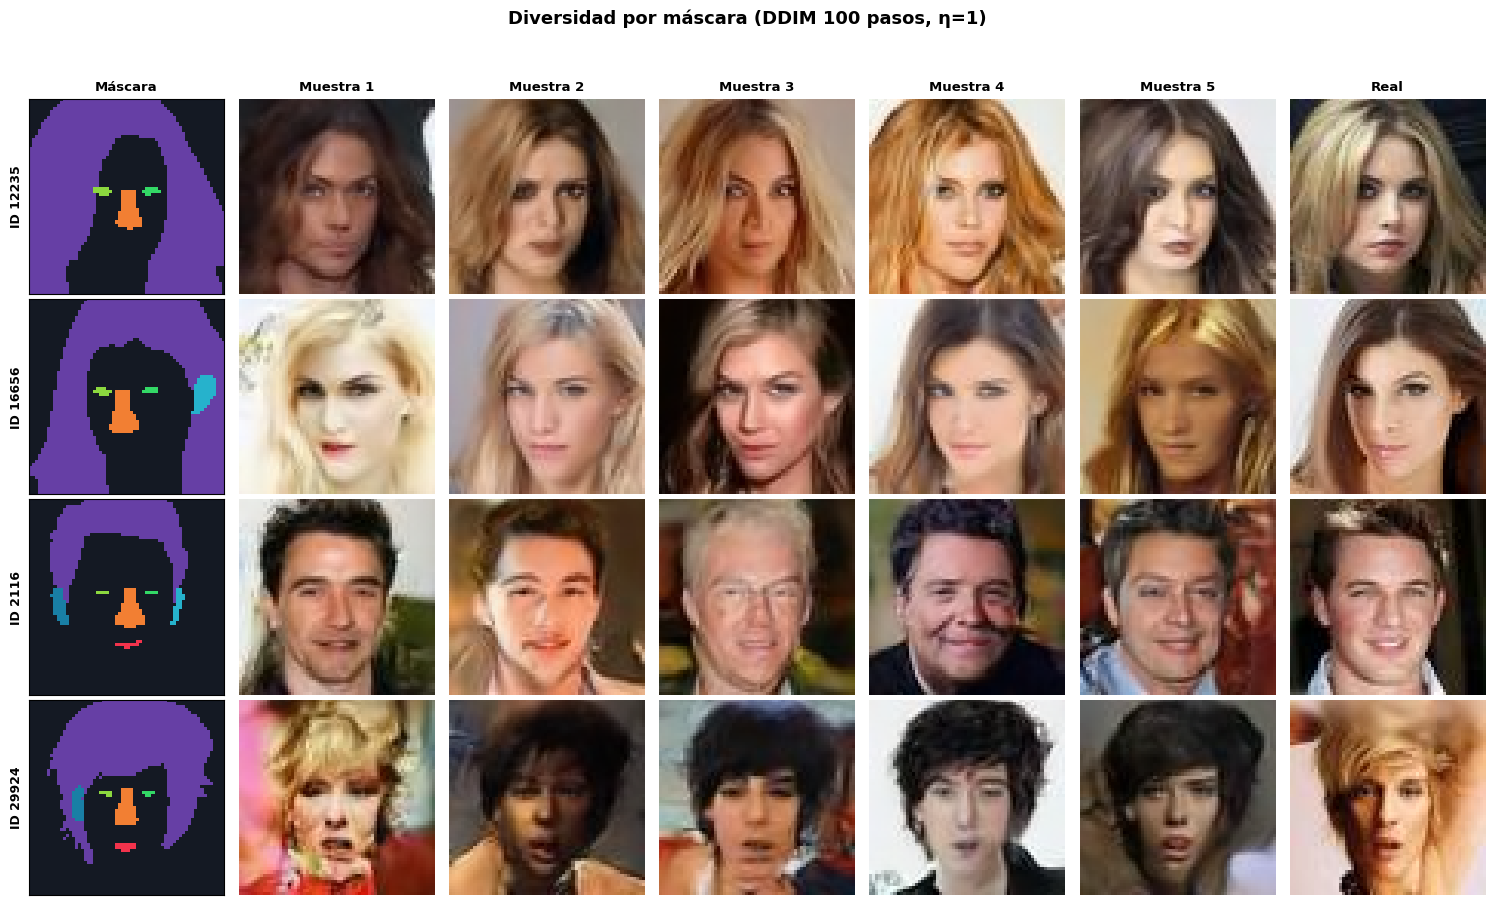

In [114]:
div_indices = qual_indices[:4]
n_variants = 5
div_masks = x_test[div_indices]

variant_batches = [
    generate(div_masks, seed=SEED + 100 + v_idx, batch_size=len(div_indices))
    for v_idx in range(n_variants)
]

fig, axes = plt.subplots(len(div_indices), n_variants + 2, figsize=(2.15 * (n_variants + 2), 2.3 * len(div_indices)))
for r_idx, t_idx in enumerate(div_indices):
    axes[r_idx, 0].imshow(colorize_mask(x_test[t_idx]))
    axes[r_idx, 0].set_ylabel(f"ID {ids_test[t_idx]}", fontsize=9, fontweight="bold")
    axes[r_idx, 0].set_xticks([])
    axes[r_idx, 0].set_yticks([])
    if r_idx == 0:
        axes[r_idx, 0].set_title("Máscara", fontsize=9.5, fontweight="bold")

    for v_idx in range(n_variants):
        axes[r_idx, v_idx + 1].imshow(denormalize_image(variant_batches[v_idx][r_idx]))
        axes[r_idx, v_idx + 1].axis("off")
        if r_idx == 0:
            axes[r_idx, v_idx + 1].set_title(f"Muestra {v_idx + 1}", fontsize=9.5, fontweight="bold")

    axes[r_idx, -1].imshow(denormalize_image(y_test[t_idx]))
    axes[r_idx, -1].axis("off")
    if r_idx == 0:
        axes[r_idx, -1].set_title("Real", fontsize=9.5, fontweight="bold")

plt.suptitle(f"Diversidad por máscara ({BEST_SAMPLER_LABEL})", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

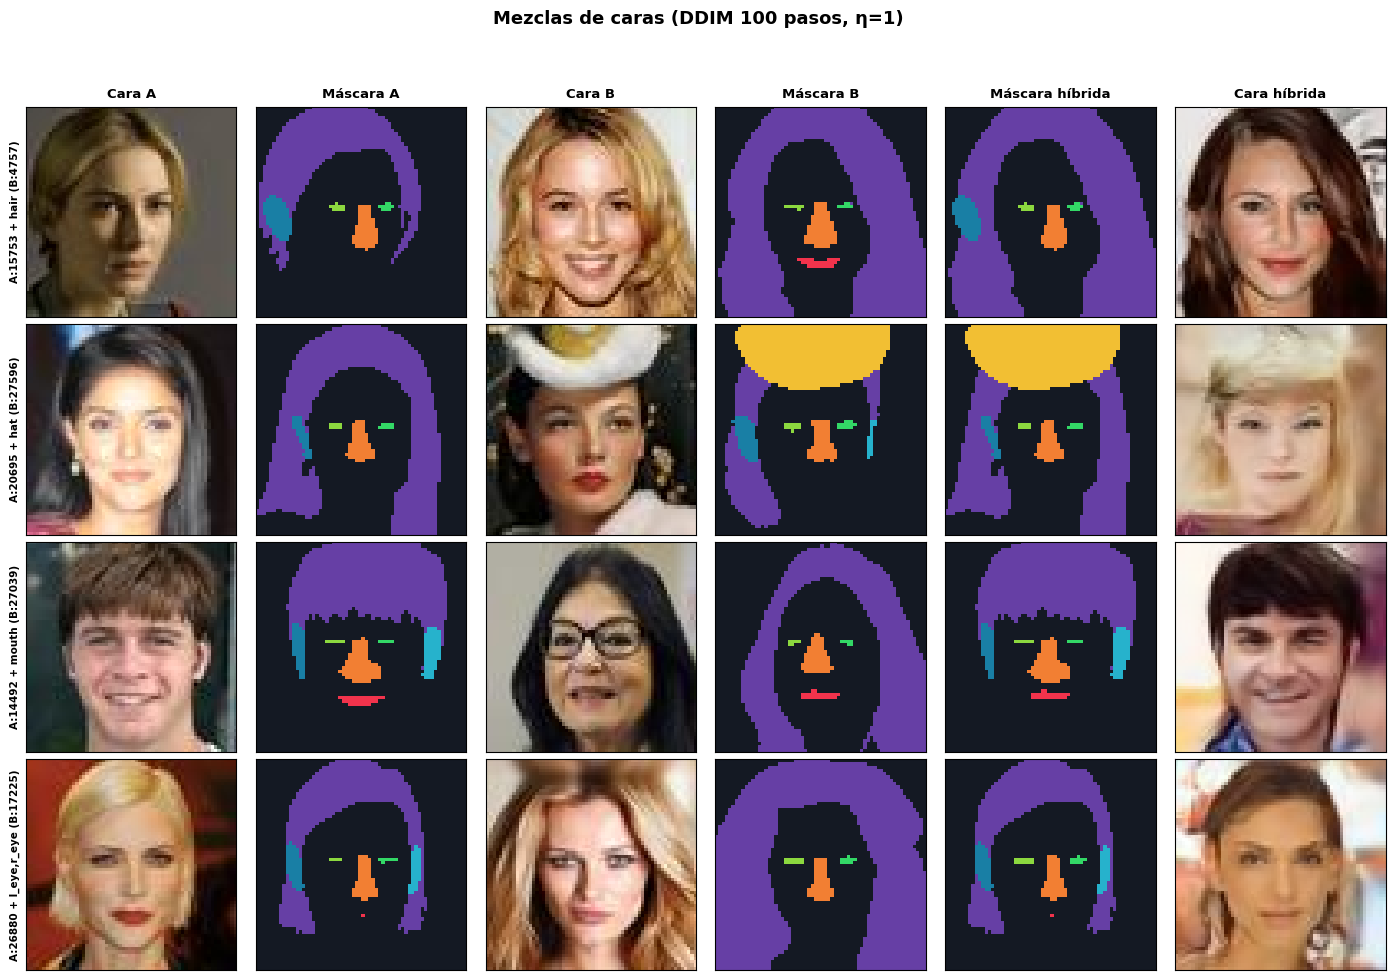

(array([[[[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         ...,
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [1., 0., 0., ..., 0., 0., 0.],
          [1.

In [115]:
SPLIT_STORE = {
    "test": (x_test, y_test, ids_test),
    "val": (x_val, y_val, ids_val),
}

DEFAULT_ATTRS_OPTIONS = [
    ["hair"],
    ["hat"],
    ["mouth"],
    ["l_eye", "r_eye"],
    ["hair", "hat"],
    ["l_ear", "r_ear"],
    ["nose"],
]

GRID_PAIRS = [
    (1387, 378, ["hair"]),
    (1277, 745, ["hat"]),
    (1363, 344, ["mouth"]),
    (1816, 1900, ["l_eye", "r_eye"]),
]


def _resolve_split_index(idx_or_id, ids_arr: np.ndarray) -> int:
    if isinstance(idx_or_id, str):
        matches = np.where(ids_arr == idx_or_id)[0]
        if len(matches) == 0:
            raise ValueError(f"ID '{idx_or_id}' no encontrado en el split.")
        return int(matches[0])
    idx = int(idx_or_id)
    if 0 <= idx < len(ids_arr):
        return idx
    matches = np.where(ids_arr == str(idx))[0]
    if len(matches) > 0:
        return int(matches[0])
    raise IndexError(f"Índice o ID {idx_or_id} fuera de rango para split de tamaño {len(ids_arr)}.")


def hybridize_masks(
    mask_a: np.ndarray,
    mask_b: np.ndarray,
    attrs_from_b: list[str],
    mask_classes: list[str] = MASK_CLASSES,
) -> np.ndarray:
    """Combina mask_a reemplazando los canales indicados con los de mask_b."""
    hybrid = mask_a.copy()
    for attr in attrs_from_b:
        if attr in mask_classes:
            c_idx = mask_classes.index(attr)
            hybrid[:, :, c_idx] = mask_b[:, :, c_idx]
    return hybrid


def random_pairs(
    n_pairs: int,
    seed: int,
    n_total: int | None = None,
    attrs_options: list[list[str]] = DEFAULT_ATTRS_OPTIONS,
    split: str = "test",
) -> list[tuple[int, int, list[str]]]:
    """Genera pares aleatorios de máscaras y atributos (reproducible por semilla)."""
    if n_total is None:
        n_total = len(SPLIT_STORE[split][0])
    rng = np.random.default_rng(seed)
    options = [opt for opt in ([a for a in o if a in MASK_CLASSES] for o in attrs_options) if opt]
    return [
        (ia, (ia + 1 + int(rng.integers(n_total - 1))) % n_total, options[int(rng.integers(len(options)))])
        for ia in rng.integers(n_total, size=n_pairs).tolist()
    ]


def mix_faces(
    recipes: list[tuple[int | str, list[tuple[int | str, list[str]]]]],
    split: str = "test",
    seed: int = SEED,
    steps: int | None = None,
    eta: float | None = None,
    save_path: Path | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    """Mezcla atributos de 2 o 3 personas según una lista de recetas y dibuja el resultado."""
    x_s, y_s, ids_s = SPLIT_STORE[split]
    resolved_recipes = []
    hybrid_list = []

    for base_raw, donors_raw in recipes:
        i_base = _resolve_split_index(base_raw, ids_s)
        hybrid_mask = x_s[i_base].copy()
        resolved_donors = []
        for donor_raw, attrs_raw in donors_raw:
            i_donor = _resolve_split_index(donor_raw, ids_s)
            attrs = [a for a in attrs_raw if a in MASK_CLASSES]
            hybrid_mask = hybridize_masks(hybrid_mask, x_s[i_donor], attrs)
            resolved_donors.append((i_donor, attrs))
        resolved_recipes.append((i_base, resolved_donors))
        hybrid_list.append(hybrid_mask)

    hybrid_masks = np.stack(hybrid_list, axis=0)
    hybrid_faces = generate(hybrid_masks, steps=steps, eta=eta, seed=seed)

    max_donors = max(len(donors) for _, donors in resolved_recipes)
    n_rows = len(resolved_recipes)
    n_cols = 2 * (1 + max_donors) + 2
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.35 * n_cols, 2.45 * n_rows), squeeze=False)

    person_letters = [chr(ord("A") + k) for k in range(1 + max_donors)]
    headers = []
    for letter in person_letters:
        headers += [f"Cara {letter}", f"Máscara {letter}"]
    headers += ["Máscara híbrida", "Cara híbrida"]

    for row_idx, (i_base, donors) in enumerate(resolved_recipes):
        panels = [
            denormalize_image(y_s[i_base]),
            colorize_mask(x_s[i_base]),
        ]
        ylabel_parts = [f"A:{ids_s[i_base]}"]
        for d_idx, (i_donor, attrs) in enumerate(donors):
            letter = chr(ord("B") + d_idx)
            panels += [
                denormalize_image(y_s[i_donor]),
                colorize_mask(x_s[i_donor]),
            ]
            ylabel_parts.append(f"{','.join(attrs)} ({letter}:{ids_s[i_donor]})")
        panels += [
            colorize_mask(hybrid_masks[row_idx]),
            denormalize_image(hybrid_faces[row_idx]),
        ]

        for col_idx in range(n_cols):
            ax = axes[row_idx, col_idx]
            if col_idx < len(panels):
                ax.imshow(panels[col_idx])
                if row_idx == 0:
                    ax.set_title(headers[col_idx], fontsize=9.5, fontweight="bold")
                if col_idx == 0:
                    ax.set_ylabel(" + ".join(ylabel_parts), fontsize=7.5, fontweight="bold")
                ax.set_xticks([])
                ax.set_yticks([])
            else:
                ax.axis("off")

    fig.suptitle(f"Mezclas de caras ({BEST_SAMPLER_LABEL})", fontsize=13, fontweight="bold", y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    if save_path is not None:
        fig.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.show()
    return hybrid_masks, hybrid_faces


mix_faces(
    [(ia, [(ib, attrs)]) for ia, ib, attrs in GRID_PAIRS],
    seed=SEED + 22,
    save_path=CHECKPOINT_DIR / "diffusion_mix_grid.png",
)

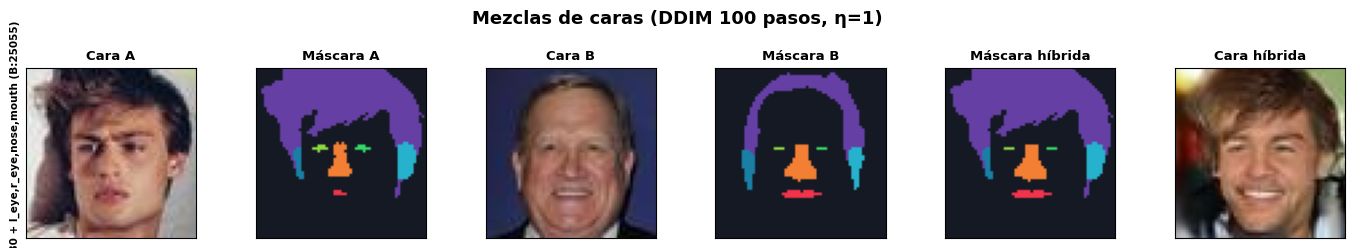

(array([[[[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         ...,
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0.

In [116]:
# Ejemplo de mezcla de 2 personas
mix_faces([(20, [(30, ["l_eye", "r_eye", "nose", "mouth"])])])

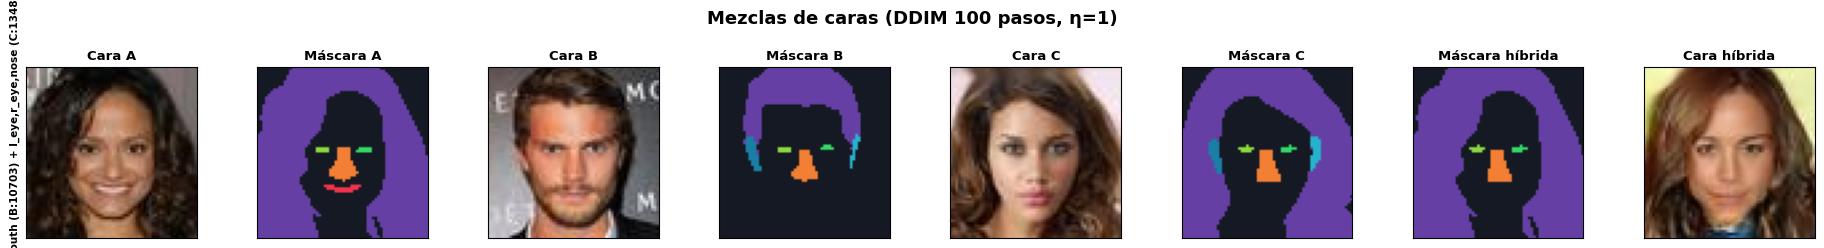

(array([[[[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         [[0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          ...,
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.],
          [0., 0., 0., ..., 0., 0., 0.]],
 
         ...,
 
         [[1., 0., 0., ..., 0., 0., 0.],
          [1., 0., 0., ..., 0., 0., 0.],
          [1., 0., 0., ..., 0., 0., 0.],
          ...,
          [1., 0., 0., ..., 0., 0., 0.],
          [1.

In [117]:
# Ejemplo de mezcla de 3 personas
mix_faces([(10, [(71, ["mouth"]), (84, ["l_eye", "r_eye", "nose"])])])

---

## **8. Evaluación cuantitativa final**

Evaluamos el modelo final con la **mejor configuración de muestreo seleccionada en la Sección 6** (DDIM con 100 pasos y eta=1) sobre el conjunto completo de **`3.000` muestras**:

- **Evaluación en caras nuevas (`3.000`):** generamos `3.000` caras nuevas combinando máscaras de pares aleatorios de `test` (`random_pairs(...)`) y calculamos su `FID`.
- **Suelo real (`val` vs `test`, `3.000`):** FID entre dos particiones reales distintas, que marca la cota inferior alcanzable para este modelo

In [118]:
FORCE_EVAL = False


def evaluate_diffusion_model() -> pd.DataFrame:
    y_test_pred = generate(x_test, seed=SEED)

    y_test_01 = denormalize_image(y_test)
    y_val_01 = denormalize_image(y_val)
    paired_01 = denormalize_image(y_test_pred)

    l1_mae = float(np.mean(np.abs(y_test_01 - paired_01)))
    one_minus_ssim = 1.0 - float(
        tf.reduce_mean(
            tf.image.ssim(
                tf.convert_to_tensor(y_test_01, dtype=tf.float32),
                tf.convert_to_tensor(paired_01, dtype=tf.float32),
                max_val=1.0,
            )
        ).numpy()
    )

    feats_real_test = extract_inception_features(y_test_01)
    feats_real_val = extract_inception_features(y_val_01)
    feats_paired = extract_inception_features(paired_01)

    fid_paired = compute_fid_from_features(feats_real_test, feats_paired)
    floor_fid = compute_fid_from_features(feats_real_test, feats_real_val)

    new_pairs = random_pairs(n_pairs=NEW_FACES_N, seed=SEED + 2025)
    x_new_masks = np.stack(
        [hybridize_masks(x_test[ia], x_test[ib], attrs) for ia, ib, attrs in new_pairs],
        axis=0,
    )
    new_faces_01 = denormalize_image(generate(x_new_masks, seed=SEED + 2025))
    feats_new = extract_inception_features(new_faces_01)
    fid_new = compute_fid_from_features(feats_real_test, feats_new)

    rows = [
        {
            "Modelo": NOTEBOOK_NAME,
            "L1 (MAE)": f"{l1_mae:.4f}",
            "1 - SSIM": f"{one_minus_ssim:.4f}",
            "FID emparejado (3k)": f"{fid_paired:.2f}",
            "FID caras nuevas (3k)": f"{fid_new:.2f}",
        },
        {
            "Modelo": "Suelo real (val vs test)",
            "L1 (MAE)": "-",
            "1 - SSIM": "-",
            "FID emparejado (3k)": f"{floor_fid:.2f}",
            "FID caras nuevas (3k)": f"{floor_fid:.2f}",
        },
    ]
    return pd.DataFrame(rows)


if not TRAIN_MODEL and not FORCE_EVAL and METRICS_CSV_PATH.exists():
    metrics_df = pd.read_csv(METRICS_CSV_PATH)
    print(f"Métricas cargadas de {METRICS_CSV_PATH.name}:")
    display(metrics_df)
else:
    metrics_df = evaluate_diffusion_model()
    metrics_df.to_csv(METRICS_CSV_PATH, index=False)
    print(f"Evaluación completada ({BEST_SAMPLER_LABEL}) y guardada en {METRICS_CSV_PATH.name}:")
    display(metrics_df)

Métricas cargadas de diffusion_generator_metrics.csv:


,Modelo,L1 (MAE),1 - SSIM,FID emparejado (3k),FID caras nuevas (3k)
0,diffusion_generator,0.2510,0.6726,14.77,14.86
1,Suelo real (val vs test),-,-,7.64,7.64


---

## **9. Conclusiones y trabajo futuro**

Los resultados en cuanto a FID son prácticamente inmejorables para un modelo tan reducido y entrenado desde cero. La generación de caras nuevas a partir de máscaras es un problema bastante complejo, y este modelo logra resultados muy realistas y coherentes con las máscaras dadas.

También hay que tener en cuenta que, al poder variar la semilla de ruido inicial, es posible generar infinitas caras distintas para la misma máscara, por lo que para obtener caras muy realistas, basta con ajustar la semilla de forma adecuada. Con nuestra capacidad de cómputo, que todas las semillas diesen buenos resultados es muy poco probable.